# Project explanation: implementation, research foundation and contribution

**A reading companion to `SNA_Project_with_Results.ipynb`**  
**Project:** Stability-Aware Structural Weighting for Fast Label Propagation in Social Networks  
**Course:** DSE 4403 / Social Network Analysis  
**Team:** Aditya Kosuru (230968316), Jaswanth P (230968014), Prithvi Ram Perivela (230968304)

Read the overview first, then follow the explanations of **all 21 original cells**, including **all 10 code cells**. Each original cell is reproduced below its explanation. Original cell numbers count both Markdown and code cells; the separate code-cell number identifies the ten executable cells. Four extra, clearly labelled demonstrations at the end show the data files, weighted votes, stability calculation and provenance.

This file uses the requested name, **`explaination.ipynb`**. Open it beside the original notebook, or select the **SNA Project (Python 3.12)** kernel and run all cells from the project folder. Outputs are already saved. Executing this companion runs the original live examples and audits the bundled experiment records; the full experimental workflow is explained separately below.

## 1. Brief overview: how the project works

The project finds **communities**: groups of nodes whose connections suggest a shared structure. A node can represent a club member, dolphin, football team or email account. An edge represents a relationship or interaction. Each node receives one community assignment; overlapping membership is outside this implementation.

The baseline is **Fast Label Propagation (FLPA)**. Initially, every node has a different temporary community label. A node looks at its neighbours' current labels and adopts a label with the highest support. Updates happen immediately. A queue schedules nodes affected by a change, avoiding repeated scans of the entire network. Random initial order and tie choices can produce different partitions across seeds.

Our proposed extension gives existing edges different voting strengths using **Jaccard neighbourhood overlap**. Edges with more shared neighbours receive a larger weight. A second switch retains a node's current label when it is already tied for maximum support. We evaluate weighting and retention separately, because either can affect the outcome. We also control the queue policy, which changes between the exact paper baseline and the experimental variants.

The complete flow is:

```text
Raw graph sources / seeded SBM generation
                 |
                 v
data.py: clean topology, stable node IDs, provenance
                 |
        +--------+---------------------------+
        |                                    |
        v                                    v
nodes.csv + edges.csv                 labels.csv, when available
        |                                    |
        v                                    | used for scoring
algorithms.py                                | and development selection
  original FLPA                              | on development graphs only
  Jaccard weights + controlled variants       |
  LPA / Leiden / NetworkX references          |
        |                                    |
        v                                    v
partition.csv + record.json ------> evaluation.py
                                           |
                       quality, stability, group sizes, timing
                                           |
                     summaries / figures / report / notebooks
```

**There is no neural-model training.** No GNN, learned embedding, optimiser, loss function or gradient update is implemented. The detector is an unsupervised graph algorithm. The scalar `lambda` is selected using 80 development experiments, then frozen at **0.25**. This is hyperparameter selection using planted development labels, rather than neural training. The **1,040 final runs** are separate graph/method/seed experiments, not training epochs. Detection itself receives topology and optional structural weights, never the evaluation labels.

## 2. What comes from the research paper, and what is our contribution?

The base paper is Traag and Šubelj (2023), [*Large network community detection by fast label propagation*](https://doi.org/10.1038/s41598-023-29610-z), Scientific Reports 13, 2701. The saved paper is `research/papers/R01.pdf`; its searchable text is `research/sources/R01/full_text.txt`. Algorithm 3 describes the FLPA baseline. The paper also discusses retention in its retention-strategy subsection.

| Part | Origin and role in this project | Where to inspect |
|---|---|---|
| Unique initial labels, asynchronous neighbour voting, random maximal-label selection | Reimplementation of the paper's original FLPA behaviour | `algorithms.py`: `propagate()`; `run_method(..., "flpa_original", ...)` |
| Queue only affected neighbours whose labels differ from the new label; avoid duplicates | Core scheduling idea from the paper's Algorithm 3 | `queue_policy="original_filtered"`, `deque`, `in_queue` |
| Keeping an already maximal current label | Established retention strategy discussed in the base paper; not an invention of this project | `retain=True` and methods C01/C11 |
| Similarity weighting and Jaccard similarity | Established ideas in graph analysis and related community-detection work | R03/R05/R10 and `research/review_notes.json` |
| Fixed edge rule `1 + lambda * Jaccard`, combined with explicit retention and queue switches | The specific proposed extension implemented and tested here | `edge_similarity()`, `apply_weights()`, C10/C11 |
| Controlled comparisons, development-only lambda selection, saved-run audits, mixed-outcome analysis | The project's experimental contribution and implementation work | `experiment.py`, `evaluation.py`, configs, tests, notebook |
| Asynchronous LPA, Leiden and NetworkX weighted FLPA | Existing comparison algorithms, called through adapters | `run_method()`, `prepare_leiden()`, `run_leiden()` |
| Ten-paper review | Research context used to justify choices and assess prior art | `research/bibliography.json`, `literature_review.csv`, `review_notes.json` |

**How to describe the novelty accurately:** “We implement and evaluate a fixed local Jaccard-weighted FLPA design, with retention and scheduling controls, and measure when it changes quality and repeatability.” Global originality of the combination has **not** been established. Adding weights alone is not enough to establish research novelty; weighted propagation already exists, including the NetworkX reference included here. The study does not establish universal superiority, and the report includes unsuccessful cases.

The other reviewed papers are not all implemented as algorithms. In particular, reviewing graph-attention and embedding papers does not mean this code trains those models. Their inputs and training protocols differ from this topology-only experiment. This project reproduces the base FLPA update rule and conducts its own smaller experiments; it does not reproduce the paper's largest-network runtime study.

## 3. What data is imported, and where does it come from?

`prepare_real()` acquires the original sources; `save_prepared()` creates the common representation. Notebook cells usually **load the already prepared files**, so they do not download datasets again. The research papers supply methods and context; the network datasets supply the nodes and edges processed by the detector.

| Dataset ID | Meaning of nodes and edges | Acquisition and raw files | Prepared size / evaluation labels |
|---|---|---|---|
| `karate` | Club members and social ties | [`nx.karate_club_graph()`](https://networkx.org/documentation/stable/reference/generated/networkx.generators.social.karate_club_graph.html); raw snapshot `data/raw/karate/networkx_graph.json` | 34 nodes, 78 edges; two club factions from the original `club` attribute |
| `dolphins` | Dolphins and association ties | [Newman archive](https://websites.umich.edu/~mejn/netdata/dolphins.zip); `data/raw/dolphins/dolphins.zip` and extracted GML | 62 nodes, 159 edges; no validated two-group labels in this downloaded archive, so reference ARI/NMI are unavailable |
| `football` | Teams and played games | [Newman archive](https://websites.umich.edu/~mejn/netdata/football.zip); `data/raw/football/football.zip` and extracted GML | 115 nodes, **613** edges; 12 conferences from GML `value`. This source differs from the paper's 616-edge version |
| `email_eu_core` | Email accounts and email links | [SNAP Email-Eu-core](https://snap.stanford.edu/data/email-Eu-core.html); `data/raw/email_eu_core/email-Eu-core.txt.gz` and `department-labels.txt.gz` | 1,005 nodes, 16,064 undirected edges after preparation; 42 department labels used as proxy groups |
| `dev_sbm_100` to `dev_sbm_103` | Generated nodes with planted groups and probabilistic edges | `nx.stochastic_block_model()`; settings saved in `data/raw/<id>/generation.json` | Four development graphs, each 200 nodes in four groups of 50; `p_in=.15`, `p_out=.01`; graph seeds 100–103 |
| `test_sbm_<low/medium/high>_<200/201/202>` | Generated stress-test networks | Same generator, separately specified settings and seeds | Nine graphs, each 400 nodes in four groups of 100; `p_in=.16`, `p_out=.005/.025/.06`; seeds 200–202 |

The synthetic labels are generated block membership, not predictions. The four development graphs choose lambda; the nine final synthetic graphs measure generalisation to those specified conditions. Reusing a seed number across different probability settings is recorded; these are still separate graph configurations. We used SBM, rather than implementing the earlier optional LFR plan.

**Common preprocessing:** retain every source node, remove self-loops, merge repeated/reciprocal edges, convert directed links to an undirected edge if either direction exists, and discard original edge weights. Email starts with 25,571 directed edges, including 642 self-loops; the resulting graph has 19 isolates and 20 connected components. This gives every method the same input topology. Structural weights added later are derived from that topology.

### 3.1 Prepared files and the separation between inputs and answers

Each `data/processed/<dataset_id>/` folder contains:

| File / columns | Meaning | How the code uses it |
|---|---|---|
| `nodes.csv`: `internal_id`, `original_id`, `original_name` | Stable node identity and source-name mapping | `load_prepared()` adds all `internal_id` values first, preserving isolates; names remain available for interpretation |
| `edges.csv`: `source`, `target` | Pairs of internal node IDs | `load_prepared()` builds a simple `nx.Graph` from these pairs |
| `labels.csv`: `internal_id`, `reference_group` | Known comparison groups, when supplied or generated | Returned separately as `PreparedGraph.labels`; passed to `evaluate()`, never `run_method()` |
| `metadata.json` | Source URL, graph hash, sizes, preprocessing, raw-file hashes, generation settings | Checks identity and records provenance |

Original IDs are sorted by type name and their **string** representation before assigning internal IDs. Therefore the prepared Karate ID `2` maps to original ID `10`, not necessarily original ID `2`. Join using the mapping, never by assuming the numbers stayed unchanged. Canonical community IDs are also arbitrary identifiers; group 0 has no intrinsic meaning and need not equal reference group 0.

`load_prepared(ROOT, "karate")` returns a `PreparedGraph` object:

```python
item.graph       # NetworkX graph, with no reference-label node attributes
item.labels      # {internal_id: reference_group}, or None
item.metadata    # source and processing record
item.graph_hash  # verifies the reconstructed topology
item.path        # processed dataset directory
```

The algorithm creates another dictionary, `result.labels`, holding **predicted community IDs**. Although both fields are named `labels`, they serve different purposes: `item.labels` is evaluation reference information; `result.labels` is the algorithm output. The call `evaluate(item.graph, result.labels, item.labels)` is where those two are compared. Keeping them separate prevents reference answers from influencing neighbour votes.

## 4. Main components and how they connect

All module names below refer to `src/sna_project/`.

| Component | Responsibility and reason for separating it | Called by |
|---|---|---|
| `contracts.py` | `PreparedGraph` / `AlgorithmResult` data objects, canonical community IDs, deterministic hashes and atomic JSON writes | Data loader, algorithms and experiment runner |
| `data.py` | Download/generate sources, clean topology, save maps and labels, verify prepared graph hash | CLI preparation, runner, notebook |
| `algorithms.py` | FLPA state and queue, edge similarity, structural weights, method switches and library adapters | Parameter selection, final runner, live notebook examples |
| `evaluation.py` | Reference ARI/NMI, common-graph modularity, size diagnostics and cross-seed stability | Runner, aggregation and independent notebook audit |
| `experiment.py` | Choose lambda, read YAML configs, run seeded jobs, record component times and artifacts, aggregate comparisons | CLI `select`, `run`, `summarize` |
| `figures.py` | Generate result plots and fixed-layout community drawings from saved evidence | CLI `plot`; notebook reads the resulting PNGs |
| `cli.py` / `__main__.py` | Command-line entry points linking the stages | `python -m sna_project ...` |
| `tests/test_project.py` | Baseline parity, weights, preprocessing, repeatability, support and metric checks | `pytest -q` |
| `tools/build_notebook.py` | Assemble and execute the original results notebook | Developer/build command |
| `tools/build_report.py` | Turn measured summaries and literature into the report | Developer/build command |

The notebook is a presentation, live-example and checking layer. The reusable implementation is in the package. Defining algorithms there makes the notebook and experiment runner use the same functions, instead of maintaining two slightly different implementations.

The full computation happened through these stages:

1. `prepare`: acquire the four real graphs and generate development/final SBM graphs.
2. `select`: run C11 for 4 lambda candidates × 4 development graphs × 5 algorithm seeds = **80 runs**; save lambda **0.25**.
3. `run`: use eight methods and ten algorithm seeds on each final graph: **320 real + 720 synthetic = 1,040 runs**.
4. `summarize`: collect records and partitions into tables, stability pairs and paired differences.
5. `plot`: generate the evidence images.
6. Build the executed notebook/report from those records. The original notebook also independently recomputes the stored partition metrics.

### 4.1 Imports used in the original notebook

| Import / alias | Why imported | Used in original code cell(s) |
|---|---|---|
| `Path` | Locate the project root and construct portable file paths | 1 and paths throughout |
| `sys` | Add this folder's `src` to the import search path; print Python version | 1 |
| `json` | Parse team details, lambda selection and bibliography | 1, 10 |
| `inspect` | Show the actual installed `propagate` / `edge_similarity` source | 3, 4 |
| `numpy as np` | Approximate floating-point comparisons | 4, 7 |
| `pandas as pd` | Read CSVs, join node assignments, filter/group tables and display values | Most code cells |
| `networkx as nx` | Store graphs, build the toy example and run the reference FLPA | 3, 4 |
| `display`, `Image` from `IPython.display` | Render tables and saved PNG figures inline | Most code cells |
| `Markdown` from `IPython.display` | Available display helper; imported but unused in the original notebook | None |
| `load_prepared` | Reconstruct graphs and separate labels from processed CSVs | 2, 3, 7 |
| `propagate`, `edge_similarity` | Inspect implementation; compute local overlap | 3, 4 |
| `apply_weights`, `run_method` | Construct structural weights and run our configured detector | 3, 4 |
| `prepare_leiden`, `run_leiden` | Convert to igraph and run the existing Leiden comparator | 4 |
| `from_groups` | Convert library groups to a canonical node-to-community dictionary | 3 |
| `support_violations` | Check that final labels have locally maximal support | 3, 4 |
| `evaluate` | Compute partition diagnostics and reference agreement | 3, 4, 7 |
| `pairwise_stability` | Available evaluation helper; unused directly in the original notebook, used by the experiment module and our extra demonstration C | None in original |

`algorithms.py` also imports `Counter`, `defaultdict` and `deque` for vote counting and queue management, `random.Random` for reproducible local randomness, `math.fsum` for weighted accumulation, `copy.deepcopy` to preserve adjacency iteration order, and `time.perf_counter` for limits. Leiden's `igraph` / `leidenalg` imports occur inside its adapters. Scikit-learn's ARI/NMI functions are imported inside `evaluation.py`; there is no model fitting there.

## 5. Core algorithm and evaluation choices

For every existing undirected edge $(u,v)$, let $N(u)$ be the open neighbour set: neighbours of $u$, excluding $u$ itself.

$$J(u,v)=\frac{|N(u)\cap N(v)|}{|N(u)\cup N(v)|},\qquad
w(u,v)=1+\lambda J(u,v).$$

For candidate community $c$, support at node $u$ is

$$S_u(c)=\sum_{v\in N(u)}w(u,v)\,\mathbf{1}[\mathrm{label}(v)=c].$$

The baseline uses unit weights. Weighted variants use `structural_weight`. At lambda 0.25, weights lie between **1 and 1.25**, with some endpoints unattainable for particular topologies. An edge with zero common neighbours remains at weight 1; it is not removed. Jaccard is computed once per graph preparation for an invocation, not recalculated after every community update. The hope is that locally embedded edges carry stronger evidence, but shared neighbours do not guarantee a true community.

`propagate()` initialises labels, shuffles nodes using the seed, and creates a FIFO `deque` plus an `in_queue` set. It pops a node, accumulates neighbour support, chooses a maximal label, updates immediately, and requeues affected neighbours when a change occurs. The set prevents duplicate queued work. Isolates keep singleton labels. Weighted ties use tolerance `atol=rtol=1e-12`; unweighted support comparisons are exact. The custom implementation records queue pops, changes, enqueue count, peak queue size and termination status. A queue-pop cap `max(10000, 1000*n)` and 120-second loop check produce explicit non-success statuses if reached. Library adapters use their own stopping rules.

The original baseline preserves candidate iteration order to match NetworkX's seeded trajectory. Controlled variants sort candidate labels before seeded sampling, and use the all-changed-neighbours queue. Consequently, **C00 versus B0 measures the baseline-to-control scheduling/order change together**; it is labelled `scheduler` in the result table but does not isolate queue scheduling from candidate enumeration. Within C00/C10/C01/C11, these choices are held fixed, allowing cleaner weighting/retention comparisons. Deep-copying graphs when adding weights preserves adjacency order so copying itself does not silently alter seeded trajectories.

| Metric | What it answers | Interpretation |
|---|---|---|
| Reference ARI | Do predicted groups agree with the supplied/planted groups? | 1 = agreement; around 0 = chance-adjusted baseline; can be negative; arbitrary label numbers do not matter |
| NMI | How much group information do prediction and reference share? | 0–1 under this normalisation; missing when no reference exists |
| Modularity | How concentrated are edges inside predicted communities relative to its null model? | Computed on the **same original unweighted graph** for all methods, with resolution 1 |
| `communities` | How many groups were produced? | Descriptive; neither larger nor smaller is automatically better |
| `largest_fraction` | What fraction of nodes belongs to the largest group? | Near 1 flags possible giant-group collapse |
| `singleton_fraction` | What fraction of nodes is in one-node groups? | Helps distinguish fragmentation and isolates |
| Stability | How much do outputs agree across random seeds on the same graph/method? | Mean ARI over 45 pairs from ten runs; repeatability is distinct from reference accuracy |
| Cold method time | How much work is required for one invocation? | Feature preparation + backend conversion + algorithm; excludes common loading, scoring, plotting and output writing |

A local support check establishes that each non-isolated node's current label is maximal under the selected rule. It does not prove global modularity optimality, match to social truth, or useful communities. A one-community partition can satisfy this check and be perfectly repeatable.

## 6. File trail: from raw data to each displayed result

| Artifact | Produced by | Read/displayed by the original notebook |
|---|---|---|
| `TEAM_DETAILS.json` | Team metadata | Code cell 1 |
| `data/raw/...` | `prepare_real()` / `prepare_sbm()` | Not read directly by original cells; used in acquisition/preparation |
| `data/processed/<id>/{nodes,edges,labels}.csv`, `metadata.json` | `save_prepared()` | `load_prepared()` in code cells 2, 3 and 7 |
| `results/development/<run_id>/result.json` | `select_parameter()` | Evidence behind selection; not individually reloaded in original cells |
| `results/parameter_selection.json` | `select_parameter()` | Code cells 1 and 5 |
| `configs/real.yaml`, `configs/stress.yaml` | Declared final experiment settings | Runner reads them; original Markdown cell 11 explains their design |
| `results/runs/<attempt>/{manifest,config,environment}.json` | `run_experiment()` | Source provenance behind the audit/summaries |
| `results/runs/<attempt>/<run_id>/partition.csv` | `run_experiment()` | Every final assignment reloaded in code cell 7 |
| `results/runs/<attempt>/<run_id>/{record,diagnostics}.json` | Runner timing, metrics, status and queue/support details | `aggregate()` reads records; the notebook reads resulting summary tables |
| `results/summaries/dataset_summary.csv` | `prepare_all()` | Code cell 2 |
| `results/summaries/per_run_metrics.csv` | `aggregate()` | Loaded in code cell 1, checked in 6 and 7 |
| `results/summaries/method_summary.csv` | `aggregate()` | Loaded in code cell 1, displayed in 8 and 9 |
| `results/summaries/manifest_audit.csv` | `aggregate()` | Code cell 6 |
| `results/summaries/paired_differences.csv` | `aggregate()` | Code cell 9 |
| `results/summaries/stability_pairs.csv` | `aggregate()` / `pairwise_stability()` | Used to generate the stability image; extra demonstration C checks one group |
| `reports/figures/*.png` | `build_figures()` | Existing images embedded in code cells 2, 4, 8 and 9 |
| `research/bibliography.json` | Literature collection and indexing | Code cell 10 |
| `research/papers`, `research/sources`, review CSV/JSON | Research collection and review | Methods and discussion evidence; paper texts are not graph inputs or training data |

**Live versus loaded output:** code cell 3 computes a fresh Karate baseline, and code cell 4 computes fresh weighted and Leiden Karate examples. Code cell 7 recomputes metrics for existing partitions without rerunning their detectors. Cells 8 and 9 read official summary tables and embed pre-generated plots. The images are not regenerated when `Image(filename=...)` runs. Their creation is handled by `python -m sna_project plot`.

## 7. Cell-by-cell walkthrough

The next sections follow the original notebook order exactly. Each explanation precedes its reproduced source cell.

| Original position | Type | Code-cell number | Opening line |
|---:|---|---:|---|
| 1 | markdown | — | `Stability-Aware Structural Weighting for Fast Label Propagation` |
| 2 | code | 1 | `from pathlib import Path` |
| 3 | markdown | — | `1. System and data` |
| 4 | code | 2 | `display(Image(filename=str(ROOT / "reports/figures/architecture.png")))` |
| 5 | markdown | — | `2. Original FLPA implementation` |
| 6 | code | 3 | `print(inspect.getsource(propagate))` |
| 7 | markdown | — | `3. Structural weights and retention` |
| 8 | code | 4 | `print(inspect.getsource(edge_similarity))` |
| 9 | markdown | — | `4. Development-only parameter selection` |
| 10 | code | 5 | `display(pd.DataFrame(selection["candidates"]))` |
| 11 | markdown | — | `5. Experiment design and controls` |
| 12 | code | 6 | `audit = pd.read_csv(ROOT / "results/summaries/manifest_audit.csv")` |
| 13 | markdown | — | `6. Independent audit of saved metrics` |
| 14 | code | 7 | `loaded = {dataset_id: load_prepared(ROOT, dataset_id) for dataset_id in runs.dataset_id.unique()}` |
| 15 | markdown | — | `7. Measured results on real graphs` |
| 16 | code | 8 | `real = summary[summary.role.eq("real")]` |
| 17 | markdown | — | `8. Ablations, runtime and synthetic stress` |
| 18 | code | 9 | `differences = pd.read_csv(ROOT / "results/summaries/paired_differences.csv")` |
| 19 | markdown | — | `9. Interpretation and limitations` |
| 20 | code | 10 | `bibliography = json.loads((ROOT / "research/bibliography.json").read_text(encoding="utf-8"))` |
| 21 | markdown | — | `10. Re-run instructions` |

### Original cell 1 — Markdown: project identity and scope

**What it does:** introduces the title, course, three team members and base-paper citation. It tells the reader that the notebook accompanies the reusable `src/sna_project` package and contains real executed examples/results.

**Why it is included:** establishes authorship and the research foundation before presenting outputs. The final sentence limits the originality claim: weighted propagation and retention are established mechanisms. The project's title expresses the intended study, not proof that stability or accuracy improves everywhere.

**Data/imports:** none; Markdown is explanatory text and does not execute. The numerical evidence appears in later code cells. Read the original cell below.

# Stability-Aware Structural Weighting for Fast Label Propagation

**DSE 4403 - Social Network Analysis**  
Aditya Kosuru (230968316), Jaswanth P (230968014), Prithvi Ram Perivela (230968304)  
Base paper: Traag and Subelj, *Large network community detection by fast label propagation*, Scientific Reports 13, 2701 (2023), DOI: 10.1038/s41598-023-29610-z.

This executed notebook explains the implementation, runs live examples, independently checks the saved experiment metrics, and displays measured results. It is accompanied by the full `src/sna_project` source package. No plotted result is simulated. The extension is a controlled empirical design; weighted propagation and tie retention are established ideas, not claimed inventions.

### Original cell 2 — Code cell 1: locate the project, import code and load saved results

**Purpose:** initialise the notebook's shared state. Later cells depend on the names defined here, so run it first.

| Statement/group | How it works | Why implemented this way |
|---|---|---|
| `ROOT = Path.cwd().resolve()` and the `TEAM_DETAILS.json` check | Starts at the kernel's working directory; if necessary, searches that directory and its ancestors for the project marker | Allows execution from the project root or a child folder without hard-coding `D:` paths |
| `sys.path.insert(0, str(ROOT / "src"))` | Places this copy of the source package first in Python's import search path | The notebook uses the submitted source rather than an unrelated installed copy |
| Standard/scientific/package imports | Makes paths, JSON, tables, graphs, displays, algorithms and evaluation available | Keeps later cells focused on their specific step; the full import map is above |
| `pd.set_option(...)` | Changes how many rows/columns are shown | Improves readability without modifying data |
| `json.loads(...parameter_selection.json...)` | Parses the saved development selection into `selection` | Uses the preselected value rather than choosing lambda from final results |
| `LAMBDA = selection["selected_lambda"]` | Reads **0.25** | Keeps the live weighted example consistent with final experiments |
| Two `pd.read_csv(...)` calls | Loads method-level aggregates into `summary` and individual final-run rows into `runs` | Distinguishes aggregate presentation from auditable per-run evidence |
| Version/status prints and team display | Shows the runtime environment, selected value, final-run count/statuses and team order | Makes execution context and completeness visible |

**Files read:** `TEAM_DETAILS.json`, `results/parameter_selection.json`, `results/summaries/method_summary.csv`, `results/summaries/per_run_metrics.csv`. No raw network data is loaded yet. Importing a function defines access to it; it does not run the full experiment.

**Outputs/state:** `ROOT`, all imports, `selection`, `LAMBDA`, `summary` and `runs`. The table has 1,040 run rows and 104 graph/method summary groups. This root finder can search ancestors, not arbitrary sibling folders; start Jupyter in the project folder as described in the README. If the marker is absent from all ancestors, Python raises an error rather than selecting an unrelated project.

In [1]:
from pathlib import Path
import sys, json, inspect
ROOT = Path.cwd().resolve()
if not (ROOT / "TEAM_DETAILS.json").exists():
    ROOT = next(p for p in [ROOT, *ROOT.parents] if (p / "TEAM_DETAILS.json").exists())
sys.path.insert(0, str(ROOT / "src"))
import numpy as np
import pandas as pd
import networkx as nx
from IPython.display import display, Image, Markdown
from sna_project.data import load_prepared
from sna_project.algorithms import (propagate, edge_similarity, apply_weights, run_method,
                                    prepare_leiden, run_leiden, from_groups, support_violations)
from sna_project.evaluation import evaluate, pairwise_stability
pd.set_option("display.max_columns", 20)
pd.set_option("display.max_rows", 120)
selection = json.loads((ROOT / "results/parameter_selection.json").read_text())
LAMBDA = selection["selected_lambda"]
summary = pd.read_csv(ROOT / "results/summaries/method_summary.csv")
runs = pd.read_csv(ROOT / "results/summaries/per_run_metrics.csv")
print("Python:", sys.version.split()[0], "NetworkX:", nx.__version__)
print("Selected lambda:", LAMBDA)
print("Saved final runs:", len(runs), "Terminal statuses:", runs.status.value_counts().to_dict())
display(pd.DataFrame(json.loads((ROOT / "TEAM_DETAILS.json").read_text())["members"]))

Python: 3.12.15 NetworkX: 3.7
Selected lambda: 0.25
Saved final runs: 1040 Terminal statuses: {'converged': 650, 'completed': 390}


,name,registration_number
0,Aditya Kosuru,230968316
1,Jaswanth P,230968014
2,Prithvi Ram Perivela,230968304


### Original cell 3 — Markdown: explain the common data contract

**What it explains:** raw sources are preserved, every detector uses the same cleaned unweighted topology, IDs are mapped deterministically, and club/conference/department references are kept separately for evaluation.

**Why it matters:** data preparation can change community results. A weighted method must not receive extra edges or reference answers that the baseline does not receive. The Dolphins missing-label disclosure explains later blank ARI/NMI values. The Football 613-versus-616 edge note prevents claiming an exact reproduction of a different source version.

**Data/imports:** none execute here. The rules are implemented in `data.py`; the next cell loads the resulting files and checks node attributes.

## 1. System and data

Raw sources are preserved; source weights are disabled in the common baseline. Every algorithm receives a simple, undirected graph without evaluation labels. Original node IDs map to canonical internal IDs. Club, conference and department labels are stored separately for scoring. Dolphins has no validated two-group mapping in the downloaded source, so its ARI/NMI are unavailable. Football in the downloaded archive has 613 edges, whereas the base paper reports 616; this is an independent reproduction on a documented source version.

### Original cell 4 — Code cell 2: architecture, dataset sizes and input-label check

**What happens, in order:**

1. `display(Image(...architecture.png))` embeds a saved architecture diagram. `Image` reads image bytes; it does not compute the pipeline or acquire datasets.
2. `pd.read_csv(...dataset_summary.csv)` loads preparation metadata for real, development and final synthetic graphs.
3. `real_ids` lists the four real dataset identifiers. `.isin(real_ids)` filters the summary to them, and the selected columns show graph sizes, components, isolates and reference-label coverage.
4. For each real dataset, `load_prepared(ROOT, dataset_id)` reads its `metadata.json`, `nodes.csv`, `edges.csv`, and `labels.csv` if present. It reconstructs an `nx.Graph`, verifies its topology hash, and returns reference labels separately.
5. `assert all(not attrs for _, attrs in item.graph.nodes(data=True))` checks that every node's attribute dictionary is empty. Therefore this prepared graph carries no `club`, conference or department node attributes for the detector to read.

**Why:** verifies the input representation and makes the dataset scale visible before algorithm comparisons. Adding all nodes before edges is essential for retaining isolates, especially in email. The assertion checks the representation; the function signatures and call sites separately establish that reference labels are only passed to evaluation.

**Outputs/state:** architecture image, a four-row table and a confirmation message. `datasets` and `real_ids` are reused later. The loop's `item` ends as the email graph, but code cell 3 explicitly resets `item` to Karate before creating the live baseline.

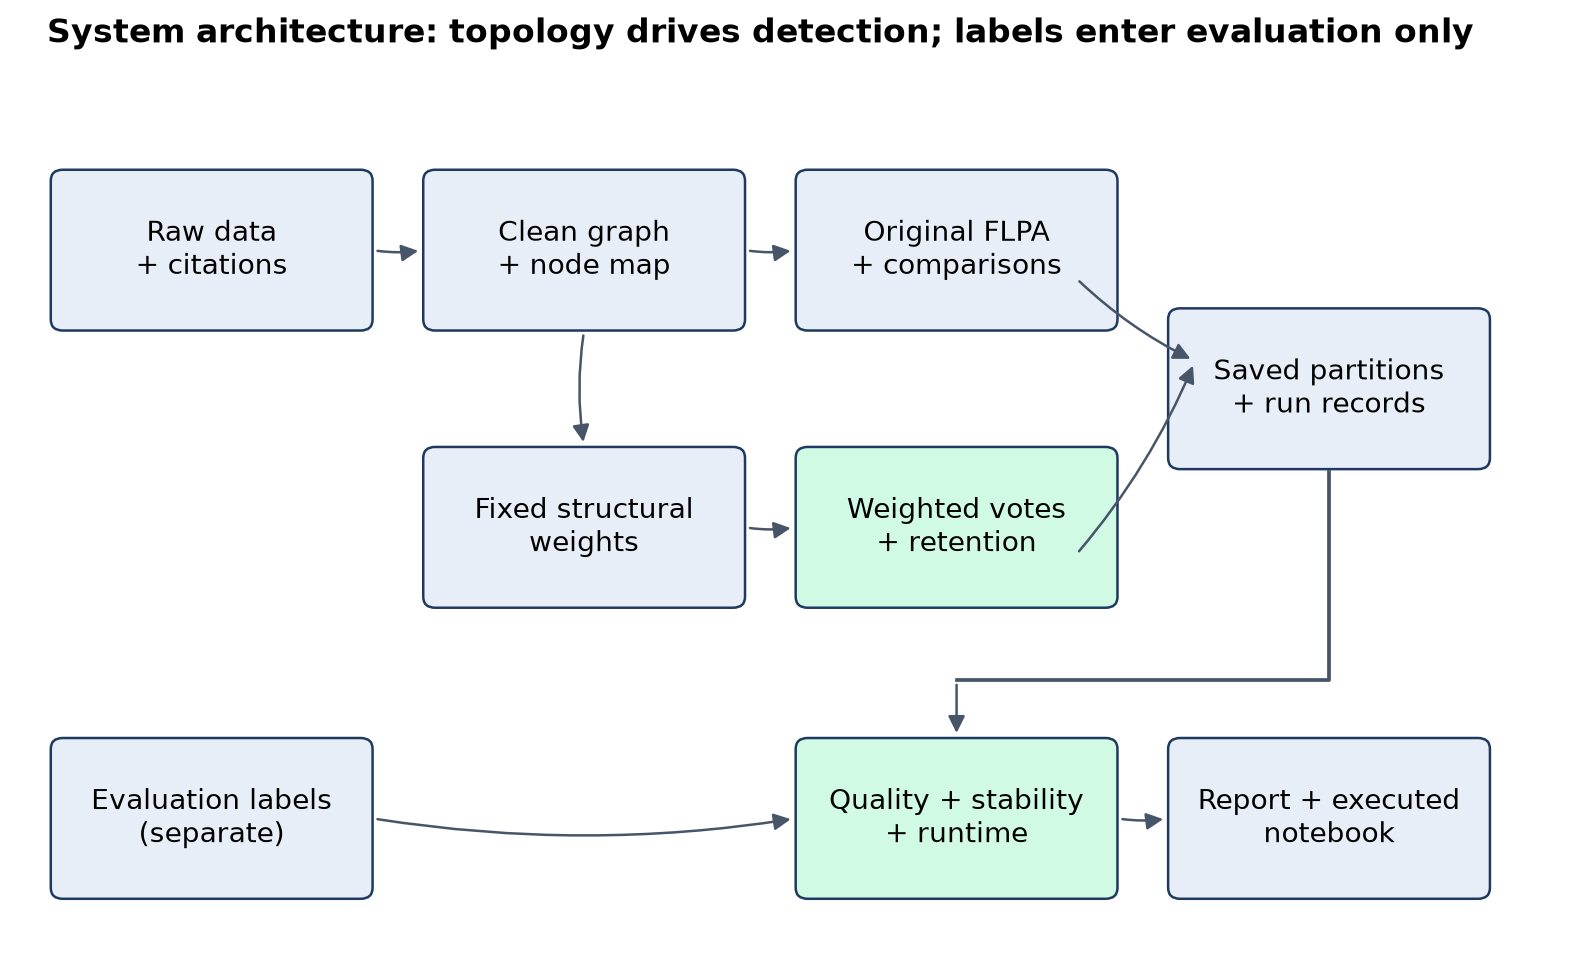

,dataset_id,nodes,edges,connected_components,isolates,reference_groups,label_coverage
0,karate,34,78,1,0,2.0,1.0
1,dolphins,62,159,1,0,NaN,0.0
2,football,115,613,1,0,12.0,1.0
3,email_eu_core,1005,16064,20,19,42.0,1.0


Checked: algorithm graphs contain no reference-label attributes.


In [2]:
display(Image(filename=str(ROOT / "reports/figures/architecture.png")))
datasets = pd.read_csv(ROOT / "results/summaries/dataset_summary.csv")
real_ids = ["karate", "dolphins", "football", "email_eu_core"]
display(datasets[datasets.dataset_id.isin(real_ids)][["dataset_id", "nodes", "edges", "connected_components", "isolates", "reference_groups", "label_coverage"]])
for dataset_id in real_ids:
    item = load_prepared(ROOT, dataset_id)
    assert all(not attrs for _, attrs in item.graph.nodes(data=True))
print("Checked: algorithm graphs contain no reference-label attributes.")

### Original cell 5 — Markdown: define the paper baseline before showing code

**What it explains:** unique initial labels, randomly initialised queue, maximal neighbour voting, immediate updates, the original filtered requeue rule, singleton isolates and the final local-support check.

**Why:** a correct baseline is necessary before an extension can be evaluated. `flpa_original` selects the original rule from a shared implementation that also supports controlled variants. The cited 50 parity cases come from `tests/test_project.py`: five graph families × ten seeds, not 50 independent empirical datasets. The next cell performs one additional live parity example.

**Data/imports:** this is documentation. Its source location is `algorithms.py`, principally `propagate()` and `run_method()`.

## 2. Original FLPA implementation

Each node starts with its own label. Nodes are processed from a randomly initialised queue. A node samples a maximal neighbour label. A change queues neighbours whose current labels differ from the new label, with duplicate queue entries prevented. Isolates retain their singleton label. A final independent check verifies maximal support.

The next cell shows the actual package implementation used by the experiments, including the switches needed for controlled variants. `flpa_original` selects unit votes, random ties and the original filtered queue. The test suite includes 50 exact comparisons against NetworkX across five graphs and ten seeds.

### Original cell 6 — Code cell 3: inspect and verify original FLPA on Karate

| Statement | Explanation and reason |
|---|---|
| `inspect.getsource(propagate)` | Prints the actual function used by the experiments. It shows queue state, vote calculation, switches, limits and result recording instead of an independent notebook-only implementation. Helpers such as `label_support()` are in the same module. |
| `item = load_prepared(ROOT, "karate")` | Loads the prepared 34-node, 78-edge graph and separate two-faction references. This assignment deliberately replaces the previous loop's `item`. |
| `base = run_method(..., "flpa_original", seed=0)` | Runs the original rule with unit votes, random maximal ties, original filtered queue, and reference candidate order. Seed 0 controls random scheduling and tie choices. Returns an `AlgorithmResult`, not a trained model. |
| `nx.community.fast_label_propagation_communities(..., weight=None, seed=0)` | Runs the existing NetworkX implementation on the same graph. `weight=None` explicitly disables edge-weight use. |
| `from_groups(..., item.graph)` | Converts NetworkX's iterable of node sets to a full, non-overlapping assignment dictionary; canonicalises group numbering. The helper returns a dictionary directly. |
| `assert base.labels == reference` | Checks exact equality after canonical numbering. It catches update-order and queue errors for this graph/seed. |
| `assert not support_violations(...)` | Independently verifies that each non-isolated node's final label has maximal unit neighbour support. |
| `evaluate(item.graph, base.labels, item.labels)` | Scores the prediction against separate faction labels and calculates modularity and group-size diagnostics. This is the first point here where reference groups participate in a numerical calculation. |

**Input files:** Karate's processed graph/map/metadata/labels. **Outputs/state:** printed implementation, parity confirmation, one-row metric table, and `item` / `base` for the next example. No partition is written by this cell. Exact parity on this example is implementation evidence; it does not mean the method is always socially accurate or globally optimal.

**Implementation details worth explaining in a viva:** `deque.popleft()` implements FIFO work; `in_queue` avoids duplicate entries; `random.Random(seed)` avoids dependence on unrelated global randomness; `reference_order=True` preserves NetworkX-compatible candidate order; `canonical_partition()` changes only group numbers, not membership.

In [3]:
print(inspect.getsource(propagate))
item = load_prepared(ROOT, "karate")
base = run_method(item.graph, "flpa_original", seed=0)
reference = from_groups(nx.community.fast_label_propagation_communities(item.graph, weight=None, seed=0), item.graph)
assert base.labels == reference
assert not support_violations(item.graph, base.labels)
print("Live baseline agrees exactly with NetworkX; status:", base.status)
display(pd.DataFrame([evaluate(item.graph, base.labels, item.labels)]))

def propagate(graph: nx.Graph, *, seed: int, weight=None, retain=False,
              queue_policy="original_filtered", reference_order=False,
              max_queue_pops=None, max_seconds=120.0, atol=1e-12, rtol=1e-12) -> AlgorithmResult:
    validate_graph(graph)
    if queue_policy not in {"original_filtered", "all_changed_neighbors"}:
        raise ValueError("Unknown queue policy")
    if atol < 0 or rtol < 0 or not math.isfinite(atol + rtol):
        raise ValueError("Invalid tie tolerance")
    rng = random.Random(seed)
    nodes = list(graph)
    labels = {node: i for i, node in enumerate(nodes)}
    rng.shuffle(nodes)
    queue, in_queue = deque(nodes), set(nodes)
    pops = changes = 0
    enqueues = len(nodes)
    peak = len(nodes)
    cap = max_queue_pops if max_queue_pops is not None else max(10000, 1000 * len(nodes))
    started = time.perf_counter()
    status = "converged"
    while queue:
        if pops >= cap:
            status = "max_queue_pops"
            break


,ari,nmi,modularity,communities,largest_fraction,singleton_fraction,label_coverage
0,0.288545,0.350168,0.364809,3,0.470588,0.0,1.0


### Original cell 7 — Markdown: define structural weights and retention

**What it explains:** the Jaccard formula, positive baseline weight, weighted label support and the retain-if-maximal tie rule. Neighbourhoods are full open neighbour sets, not sets of nodes currently assigned the same community.

**Why this design:** weights are transparent and inexpensive relative to learning an embedding. The `1 + ...` form keeps every existing edge active and makes lambda zero reduce to unit weights. Retention may reduce unnecessary tie changes. Both are hypotheses to test; neither guarantees accuracy.

**Data/imports:** none execute. The next code cell demonstrates the formula on a six-node toy graph, then applies the chosen lambda to the real Karate graph. Those are two different uses of data.

## 3. Structural weights and retention

For each existing edge, use the full open-neighbour sets:

\[
J(u,v)=\frac{|N(u)\cap N(v)|}{|N(u)\cup N(v)|},\qquad w(u,v)=1+\lambda J(u,v).
\]

A candidate label receives the sum of its incident structural weights. The current label is retained if it is already maximal within the fixed numerical tolerance. Otherwise one maximal label is sampled. Weights depend only on topology and remain fixed during each run. Weight preparation is included in the cold method cost.

### Original cell 8 — Code cell 4: toy weights, real weighted FLPA and Leiden

This cell has **two separate experiments**. Distinguishing them avoids confusing an illustration with a measured benchmark result.

**Part A — a hand-built mechanism example:** `nx.Graph([...])` creates two triangles joined by edge `(2,3)`. It is not loaded from a source dataset. `edge_similarity(example)` builds neighbour sets and computes intersection size divided by union size for every existing edge. The displayed table uses **lambda 1**, only to make the arithmetic visible.

- For edge `(0,1)`, the sets are `{1,2}` and `{0,2}`. One shared neighbour divided by three union members gives `J=1/3` and illustrative weight `4/3`.
- For `(0,2)`, the sets are `{1,2}` and `{0,1,3}`. The union has four nodes, giving `J=1/4`.
- The bridge `(2,3)` has no common neighbours, so `J=0` and its weight remains 1.
- The three assertions check these values, including approximate comparison for fractions. `weight_example.png` is a pre-generated illustration of this same mechanism at lambda 1.

**Part B — a live benchmark example:** `weighted = apply_weights(item.graph, edge_similarity(item.graph), LAMBDA)` uses **Karate**, because `item` was assigned in the previous code cell. It does not use `example`. Here `LAMBDA` is the selected **0.25**. `apply_weights()` deep-copies the graph, validates similarities, and writes an edge attribute named `structural_weight`. Deep copying preserves adjacency order so adding a feature does not unintentionally reorder seeded computation.

`run_method(weighted, "c11_weighted_retain", seed=0)` selects weighted support, retain-if-maximal, the all-changed-neighbours queue, and sorted candidate enumeration. `support_violations(..., "structural_weight")` checks the correct weighted stopping condition.

`prepare_leiden(item.graph)` converts the original topology to igraph while retaining an index-to-node mapping. `run_leiden(..., seed=0)` calls the existing Leiden library with standard modularity, unit edges and `n_iterations=-1`, letting its own optimisation stop when it no longer improves. This is an optimisation algorithm comparator, not neural training.

Finally, `live` compares the earlier baseline, C11 and Leiden. All three are scored with `evaluate(item.graph, ..., item.labels)`: **the same unweighted Karate graph and the same separate faction references**. The C11 input is weighted, but its reported modularity is deliberately calculated on the common unweighted graph so the objective scale is comparable.

**Outputs/state:** toy-edge table, weight illustration and a three-row live metric table. `example`, `similarity`, `weighted`, `modified`, `leiden` and `live` remain in memory. These seed-0 examples do not replace the ten-seed official tables displayed later. B0-to-C11 changes several choices together; controlled ablations are needed to attribute differences to weighting.

def edge_similarity(graph: nx.Graph) -> dict[tuple[int, int], float]:
    validate_graph(graph)
    neighbours = {u: set(graph[u]) for u in graph}
    similarity = {}
    for u, v in graph.edges:
        common = len(neighbours[u] & neighbours[v])
        union = len(neighbours[u]) + len(neighbours[v]) - common
        similarity[tuple(sorted((u, v)))] = common / union
    return similarity



,edge,Jaccard,weight_lambda_1
0,"(0, 1)",0.333333,1.333333
1,"(0, 2)",0.250000,1.250000
2,"(1, 2)",0.250000,1.250000
3,"(2, 3)",0.000000,1.000000
4,"(3, 4)",0.250000,1.250000
5,"(3, 5)",0.250000,1.250000
6,"(4, 5)",0.333333,1.333333


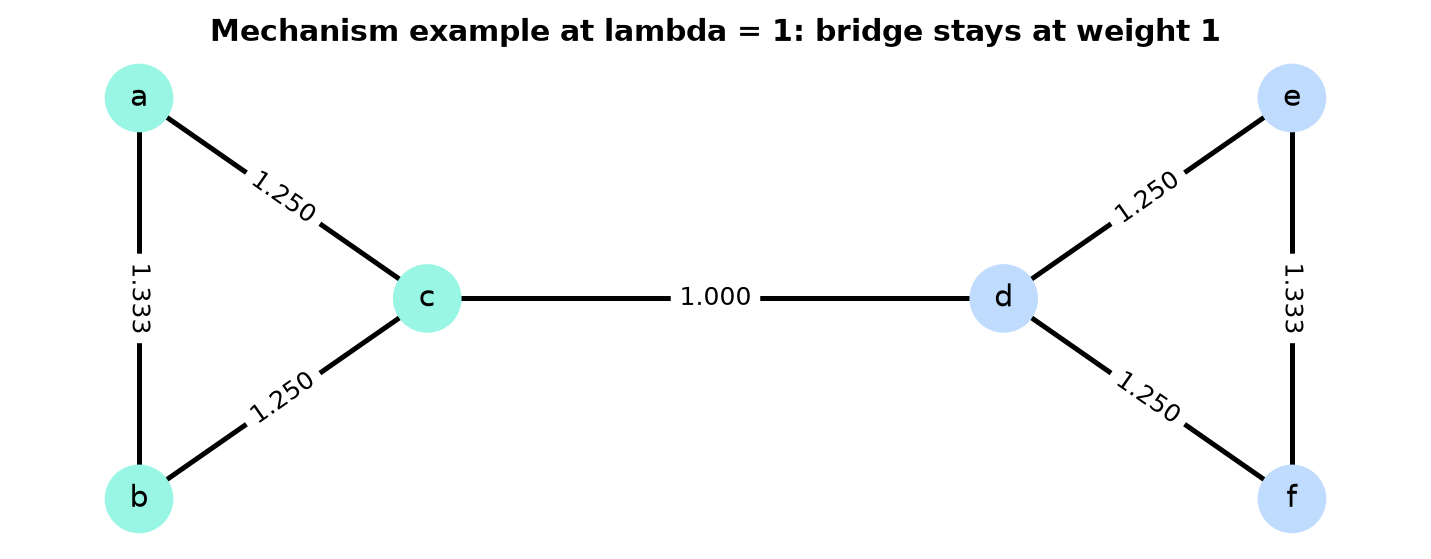

,method,ari,nmi,modularity,communities,largest_fraction,singleton_fraction,label_coverage
0,Original FLPA,0.288545,0.350168,0.364809,3,0.470588,0.0,1.0
1,Weighted + retention,0.486859,0.571131,0.394395,5,0.411765,0.0,1.0
2,Leiden,0.464591,0.587850,0.419790,4,0.352941,0.0,1.0


In [4]:
print(inspect.getsource(edge_similarity))
example = nx.Graph([(0,1),(1,2),(0,2),(3,4),(4,5),(3,5),(2,3)])
similarity = edge_similarity(example)
display(pd.DataFrame([{"edge": str(edge), "Jaccard": value, "weight_lambda_1": 1+value}
                      for edge, value in similarity.items()]))
assert np.isclose(similarity[(0,1)], 1/3)
assert np.isclose(similarity[(0,2)], 1/4)
assert similarity[(2,3)] == 0
display(Image(filename=str(ROOT / "reports/figures/weight_example.png")))
weighted = apply_weights(item.graph, edge_similarity(item.graph), LAMBDA)
modified = run_method(weighted, "c11_weighted_retain", seed=0)
assert not support_violations(weighted, modified.labels, "structural_weight")
leiden = run_leiden(prepare_leiden(item.graph), seed=0)
live = pd.DataFrame([{"method": name, **evaluate(item.graph, result.labels, item.labels)}
                     for name, result in [("Original FLPA", base), ("Weighted + retention", modified), ("Leiden", leiden)]])
display(live.round(6))

### Original cell 9 — Markdown: explain development-only parameter selection

**What it explains:** lambda candidates `{0, .25, .5, 1}`, four separate 200-node development SBM graphs, five algorithm seeds, eligibility constraints and stability-based choice.

**Why:** choosing the parameter on the same final labels used to report performance would bias the evaluation. The detector never receives planted answers, but `select_parameter()` may score its development outputs against development block labels. Real/final-test labels are excluded from that choice. The 80-run selection process was already performed by the package; the next cell reads and checks its saved decision.

**Files behind it:** generated development graphs, `results/development/*/result.json` and `results/parameter_selection.json`. This is hyperparameter tuning of a classical algorithm, not learning edge weights from examples.

## 4. Development-only parameter selection

Lambda candidates were 0, 0.25, 0.5 and 1. Four separate development SBM graphs (200 nodes; generation seeds 100-103) and five algorithm seeds were used, totalling 80 development runs. Candidates must retain reference ARI within 0.02 of lambda zero and avoid giant-group collapse on the balanced development graphs. Choose the highest mean stability, preferring a smaller lambda within 0.01. No final real/test labels were used to choose lambda.

### Original cell 10 — Code cell 5: check why lambda 0.25 was selected

**How the selection originally ran:** `experiment.py::select_parameter()` evaluates C11 for 4 candidates × 4 development graphs × 5 seeds. For each candidate, it records mean reference ARI, mean cross-seed stability, the maximum observed largest-group fraction and whether all runs passed status/support checks. A candidate is eligible only if all runs are valid, its mean ARI is at least the lambda-zero mean minus **0.02**, and no largest-group fraction exceeds **0.95**. Among eligible candidates, choose the smallest lambda within **0.01** of the best mean stability.

**What this notebook cell does:**

1. Displays `selection["candidates"]`, already loaded from `results/parameter_selection.json` in code cell 1.
2. Asserts that the selection record declares `final_labels_used` to be false.
3. Filters the stored eligibility flags, finds the best eligible mean stability, and independently recomputes the smaller-lambda preference.
4. Asserts that the resulting `expected` value equals `LAMBDA`.

The recorded lambda-zero reference ARI is about **0.89455** and stability **0.81989**. Candidates 0.25, 0.5 and 1 all have reference ARI about **0.89248** and stability **0.85851**. All are eligible, so the preference chooses **0.25**. The slight ARI reduction passes the stated tolerance; selection is a quality-constrained stability tradeoff, not simply maximum ARI.

**Why:** makes the decision inspectable and catches inconsistencies between the saved decision and the preference rule. **Scope of the check:** it trusts the stored candidate statistics and eligibility flags; it does not rerun all 80 development jobs or independently reconstruct every eligibility flag. The actual selection function and stored development results provide the additional evidence. The `final_labels_used` assertion checks a declaration, while inspecting `select_parameter()` establishes which graph IDs it actually loads.

**Outputs/state:** candidate table, eligibility list, best stability and confirmation. No new experiment records are written.

In [5]:
display(pd.DataFrame(selection["candidates"]))
assert selection["final_labels_used"] is False
eligible = [c for c in selection["candidates"] if c["eligible"]]
best = max(c["mean_stability"] for c in eligible)
expected = min(c["lambda_value"] for c in eligible if c["mean_stability"] >= best-.01)
assert expected == LAMBDA
print("Selection rule independently checked. Frozen lambda =", LAMBDA)

,lambda_value,mean_reference_ari,mean_stability,max_largest_fraction,all_runs_valid,eligible
0,0.00,0.894546,0.819892,0.765,True,True
1,0.25,0.892482,0.858510,0.270,True,True
2,0.50,0.892482,0.858510,0.270,True,True
3,1.00,0.892482,0.858510,0.270,True,True


Selection rule independently checked. Frozen lambda = 0.25


### Original cell 11 — Markdown: explain the eight methods and fair controls

**What it explains:** B0, the four C variants, asynchronous LPA, Leiden and NetworkX weighted FLPA, plus the real/synthetic experiment counts. The effective settings are stored with each attempt and originate in `configs/real.yaml` and `configs/stress.yaml`.

**Why the C variants are necessary:** C10–C00 compares weighting while retaining the same random tie rule and controlled scheduling/order; C11–C01 compares weighting under retention; C01–C00 compares retention under unit weights. C11–B0 describes the complete design change but cannot attribute the outcome to one mechanism. As explained above, C00–B0 includes candidate-order differences as well as queue scheduling.

**Data used:** four final real graphs and nine final SBM graphs. The ten algorithm seeds are 0–9; the job-schedule shuffle uses a separate seed, 2718. Graph-generation seeds create the topology; algorithm seeds control the detector's randomness; schedule seed controls execution order. These are distinct roles. All methods for a dataset use the same prepared graph.

## 5. Experiment design and controls

| ID | Weight | Tie rule | Queue |
|---|---|---|---|
| B0 | Unit | Random maximal | Original filtered |
| C00 | Unit | Random maximal | All changed neighbours |
| C10 | Structural | Random maximal | All changed neighbours |
| C01 | Unit | Retain maximal | All changed neighbours |
| C11 | Structural | Retain maximal | All changed neighbours |
| LPA | Unit | Library asynchronous LPA | Library |
| Leiden | Unit | Modularity optimisation | Library |
| NX-W | Structural | NetworkX weighted FLPA | Original filtered |

Eight configurations x ten seeds x four real graphs = 320 real runs. Nine separately generated final SBM graphs x eight configurations x ten seeds = 720 synthetic runs. Low/medium/high between-block probabilities are 0.005/0.025/0.06, with within-block probability 0.16 and four groups of 100 nodes. Generation seeds are 200-202. The synthetic experiment uses SBM rather than the optional LFR design, keeping planted structure and generation reproducible.

The scheduler control is necessary: comparing C11 with B0 alone changes weighting, ties and scheduling together. Weighting is isolated by C10-C00 and C11-C01.

### Original cell 12 — Code cell 6: check final-run counts and status

**Inputs:** `results/summaries/manifest_audit.csv`, plus `runs` loaded from `per_run_metrics.csv` in code cell 1. During the full workflow, the runner wrote an expected-job manifest for each attempt, and `aggregate()` counted actual `record.json` files to create this audit table.

**How it works:** displays the audit; asserts that summed expected and observed counts both equal **1,040**; checks the same number of per-run rows; accepts only `completed` or `converged` status; and requires all `partition_valid` flags to be true. Original/custom FLPA normally reports `converged`, while library adapters return `completed` on successful execution.

**Why:** missing or failed runs should be visible before displaying performance averages. Otherwise a method could appear better after problematic runs are silently omitted.

**Scope:** this cell checks recorded counts, statuses and validity flags. It does not independently establish that every intended dataset/method/seed tuple is unique or recompute support checks. The package validation additionally checks duplicate tuples and source fingerprints; the next cell reloads actual assignments and recomputes their metrics.

**Output/state:** the audit table, `audit` and a confirmation. No algorithms are rerun here and no final records are changed.

In [6]:
audit = pd.read_csv(ROOT / "results/summaries/manifest_audit.csv")
display(audit)
assert audit.expected.sum() == audit.observed.sum() == 1040
assert len(runs) == 1040
assert runs.status.isin(["completed", "converged"]).all()
assert runs.partition_valid.all()
print("All expected final runs exist and have valid partitions.")

,attempt,expected,observed
0,final_real_v1_20261026T145257401214Z,320,320
1,final_synthetic_v1_20261026T145312136362Z,720,720


All expected final runs exist and have valid partitions.


### Original cell 13 — Markdown: announce the independent partition audit

**What it explains:** rather than accepting every stored number, the following cell reloads each saved partition and recalculates its scores using the processed graph and separate reference labels.

**Why:** this links displayed aggregate results back to actual node assignments. It can catch mismatched files, misaligned IDs and changed metric values. Recalculating scores from a partition differs from rerunning its community detector; runtime evidence remains the originally recorded measurement.

**Data/imports:** none execute in this Markdown cell. The next code cell supplies the concrete file path and numerical checks.

## 6. Independent audit of saved metrics

This cell reloads every final partition, recomputes its metrics from the processed graph and separate labels, and checks the saved values. It does not substitute new results or select favourable seeds.

### Original cell 14 — Code cell 7: recompute metrics for all 1,040 partitions

| Statement/group | What it does and why |
|---|---|
| `loaded = {id: load_prepared(...) ...}` | Loads each of the 13 final graphs once, including separate labels and topology-hash verification. Reuses those objects across methods/seeds instead of repeatedly parsing the same CSVs. Development graphs are not in `runs`. |
| `for row in runs.itertuples(index=False)` | Visits every saved final experiment row; attribute access such as `row.run_id` identifies its partition. |
| Construct `results/runs/<attempt>/<run_id>/partition.csv` | Uses the actual attempt and run IDs from the record. This keeps an assignment tied to its recorded experiment. |
| `pd.read_csv(path)` and `dict(zip(...))` | Reads `internal_id,community_id` into integer node-to-prediction assignments. It is not a reference-label file. |
| `evaluate(graph_item.graph, labels, graph_item.labels)` | Recomputes ARI/NMI where references exist, modularity on the common original graph, community count and size fractions. The evaluator requires the assignment node set to match the graph. |
| Loop over six metric names | Checks `ari`, `nmi`, `modularity`, `communities`, `largest_fraction` and `singleton_fraction` against the per-run CSV row. |
| Missing-value branch | Dolphins ARI/NMI return Python `None`; CSV represents these as missing/NaN. Treating both as unavailable avoids inventing reference labels or treating missing as zero. |
| `np.isclose(..., atol=1e-12, rtol=1e-12)` | Allows small CSV floating-point round-trip differences. It is a numerical equality check, not a statistical significance test. |

**Why:** verifies that final score tables are consistent with the bundled graph and partition files, including the small-graph successes and the giant-community failures. Checking all rows avoids choosing only favourable seeds.

**Outputs/state:** `loaded` graph cache and the final checked count **1,040**. The cell does not recalculate algorithm timings, reproduce detector trajectories, recheck every original support diagnostic, or independently rebuild all stability aggregates. Extra demonstration C below does recalculate one stability group to explain that separate step.

In [7]:
loaded = {dataset_id: load_prepared(ROOT, dataset_id) for dataset_id in runs.dataset_id.unique()}
checked = 0
for row in runs.itertuples(index=False):
    path = ROOT / "results/runs" / row.attempt / row.run_id / "partition.csv"
    assignment = pd.read_csv(path)
    labels = dict(zip(assignment.internal_id.astype(int), assignment.community_id.astype(int)))
    graph_item = loaded[row.dataset_id]
    metrics = evaluate(graph_item.graph, labels, graph_item.labels)
    for metric in ["ari", "nmi", "modularity", "communities", "largest_fraction", "singleton_fraction"]:
        actual, stored = metrics[metric], getattr(row, metric)
        assert (actual is None and pd.isna(stored)) or np.isclose(actual, stored, atol=1e-12, rtol=1e-12)
    checked += 1
print("Independently recomputed and verified", checked, "saved final partitions.")

Independently recomputed and verified 1040 saved final partitions.


### Original cell 15 — Markdown: explain how to read real-network results

**What it explains:** Dolphins has no reference ARI/NMI, each method/dataset summary contains ten algorithm seeds, and cross-seed stability uses 45 unordered pairs.

**Why:** the same number can answer different questions. Reference ARI compares predictions to known groups; stability compares predictions to other predictions. Ten runs yield `10*9/2 = 45` pairs, but the pairs share runs and are dependent. A consistently wrong one-group result can be stable. Read stability together with reference agreement, modularity and the largest-group fraction.

**Data/imports:** no computation here; the interpretation applies to the next table and figures.

## 7. Measured results on real graphs

ARI/NMI are unavailable for Dolphins. Every group has ten algorithm seeds. Mean stability uses all 45 unordered partition pairs, which are dependent descriptive observations, not 45 independent replicates. Inspect group sizes along with stability: a constant one-group answer can be perfectly stable and uninformative.

### Original cell 16 — Code cell 8: display the official real-network evidence

**Inputs:** `summary` loaded from `results/summaries/method_summary.csv`, and `real_quality.png`, `stability.png`, `communities.png` under `reports/figures/`.

`summary.role.eq("real")` selects real-network groups, excluding final synthetic rows whose role is `test`. There are **4 datasets × 8 methods = 32 rows**. Each row summarises ten runs. The displayed columns include run count, mean/reference ARI variation, NMI, modularity, mean stability, average group count, average largest-group fraction and median cold method time. `.round(5)` changes display precision only.

The source aggregation uses arithmetic means and sample standard deviations (`ddof=1`) for valid per-run values, and medians/quartiles for time. Stability comes from ARI comparisons of partitions, not the standard deviation of accuracy. Dolphins ARI/NMI stay blank because the evaluator had no reference labels.

**Images:** `real_quality.png` compares reference quality, modularity and stability; `stability.png` shows the distribution of pairwise seed comparisons; `communities.png` uses a fixed layout per graph and displays seed-0 partitions for B0, C11 and Leiden on Karate/Dolphins/Football. The drawings are illustrations of those seeds, not evidence that every seed finds the same groups. They omit an email drawing; email remains in the numerical tables.

**Why saved figures:** plotting is a separate reproducible stage, keeping the notebook focused on inspecting the measured evidence. Calling `Image(...)` embeds an existing PNG and does not redraw it from the just-loaded table.

**How to interpret:** Karate shows improved repeatability with a reference-quality tradeoff; Football can improve reference agreement while lowering modularity; email retains a large unhelpful group for FLPA-family methods. Do not select a winner from stability alone. **Output/state:** `real`, a 32-row table and three images.

,dataset_id,method,successful_runs,ari_mean,ari_std,nmi_mean,modularity_mean,stability_mean,communities_mean,largest_fraction_mean,method_total_s_median
0,dolphins,asyn_lpa,10,NaN,NaN,NaN,0.46711,0.52199,5.0,0.40968,0.00095
1,dolphins,c00_unit_random,10,NaN,NaN,NaN,0.47610,0.56627,4.4,0.41129,0.00075
2,dolphins,c01_unit_retain,10,NaN,NaN,NaN,0.46820,0.50695,6.0,0.39355,0.00071
3,dolphins,c10_weighted_random,10,NaN,NaN,NaN,0.51749,0.85838,4.4,0.35161,0.00169
4,dolphins,c11_weighted_retain,10,NaN,NaN,NaN,0.51432,0.84971,5.8,0.35000,0.00165
5,dolphins,flpa_original,10,NaN,NaN,NaN,0.47398,0.57983,4.2,0.43387,0.00065
6,dolphins,leiden_modularity,10,NaN,NaN,NaN,0.52684,0.89164,4.6,0.32581,0.00081
7,dolphins,nx_weighted_flpa,10,NaN,NaN,NaN,0.51711,0.84826,4.5,0.35323,0.00145
8,email_eu_core,asyn_lpa,10,0.00102,0.00371,0.05529,0.01585,0.75731,20.2,0.96647,0.02686
9,email_eu_core,c00_unit_random,10,0.00019,0.00292,0.04423,0.00795,0.86280,20.1,0.97363,0.02586


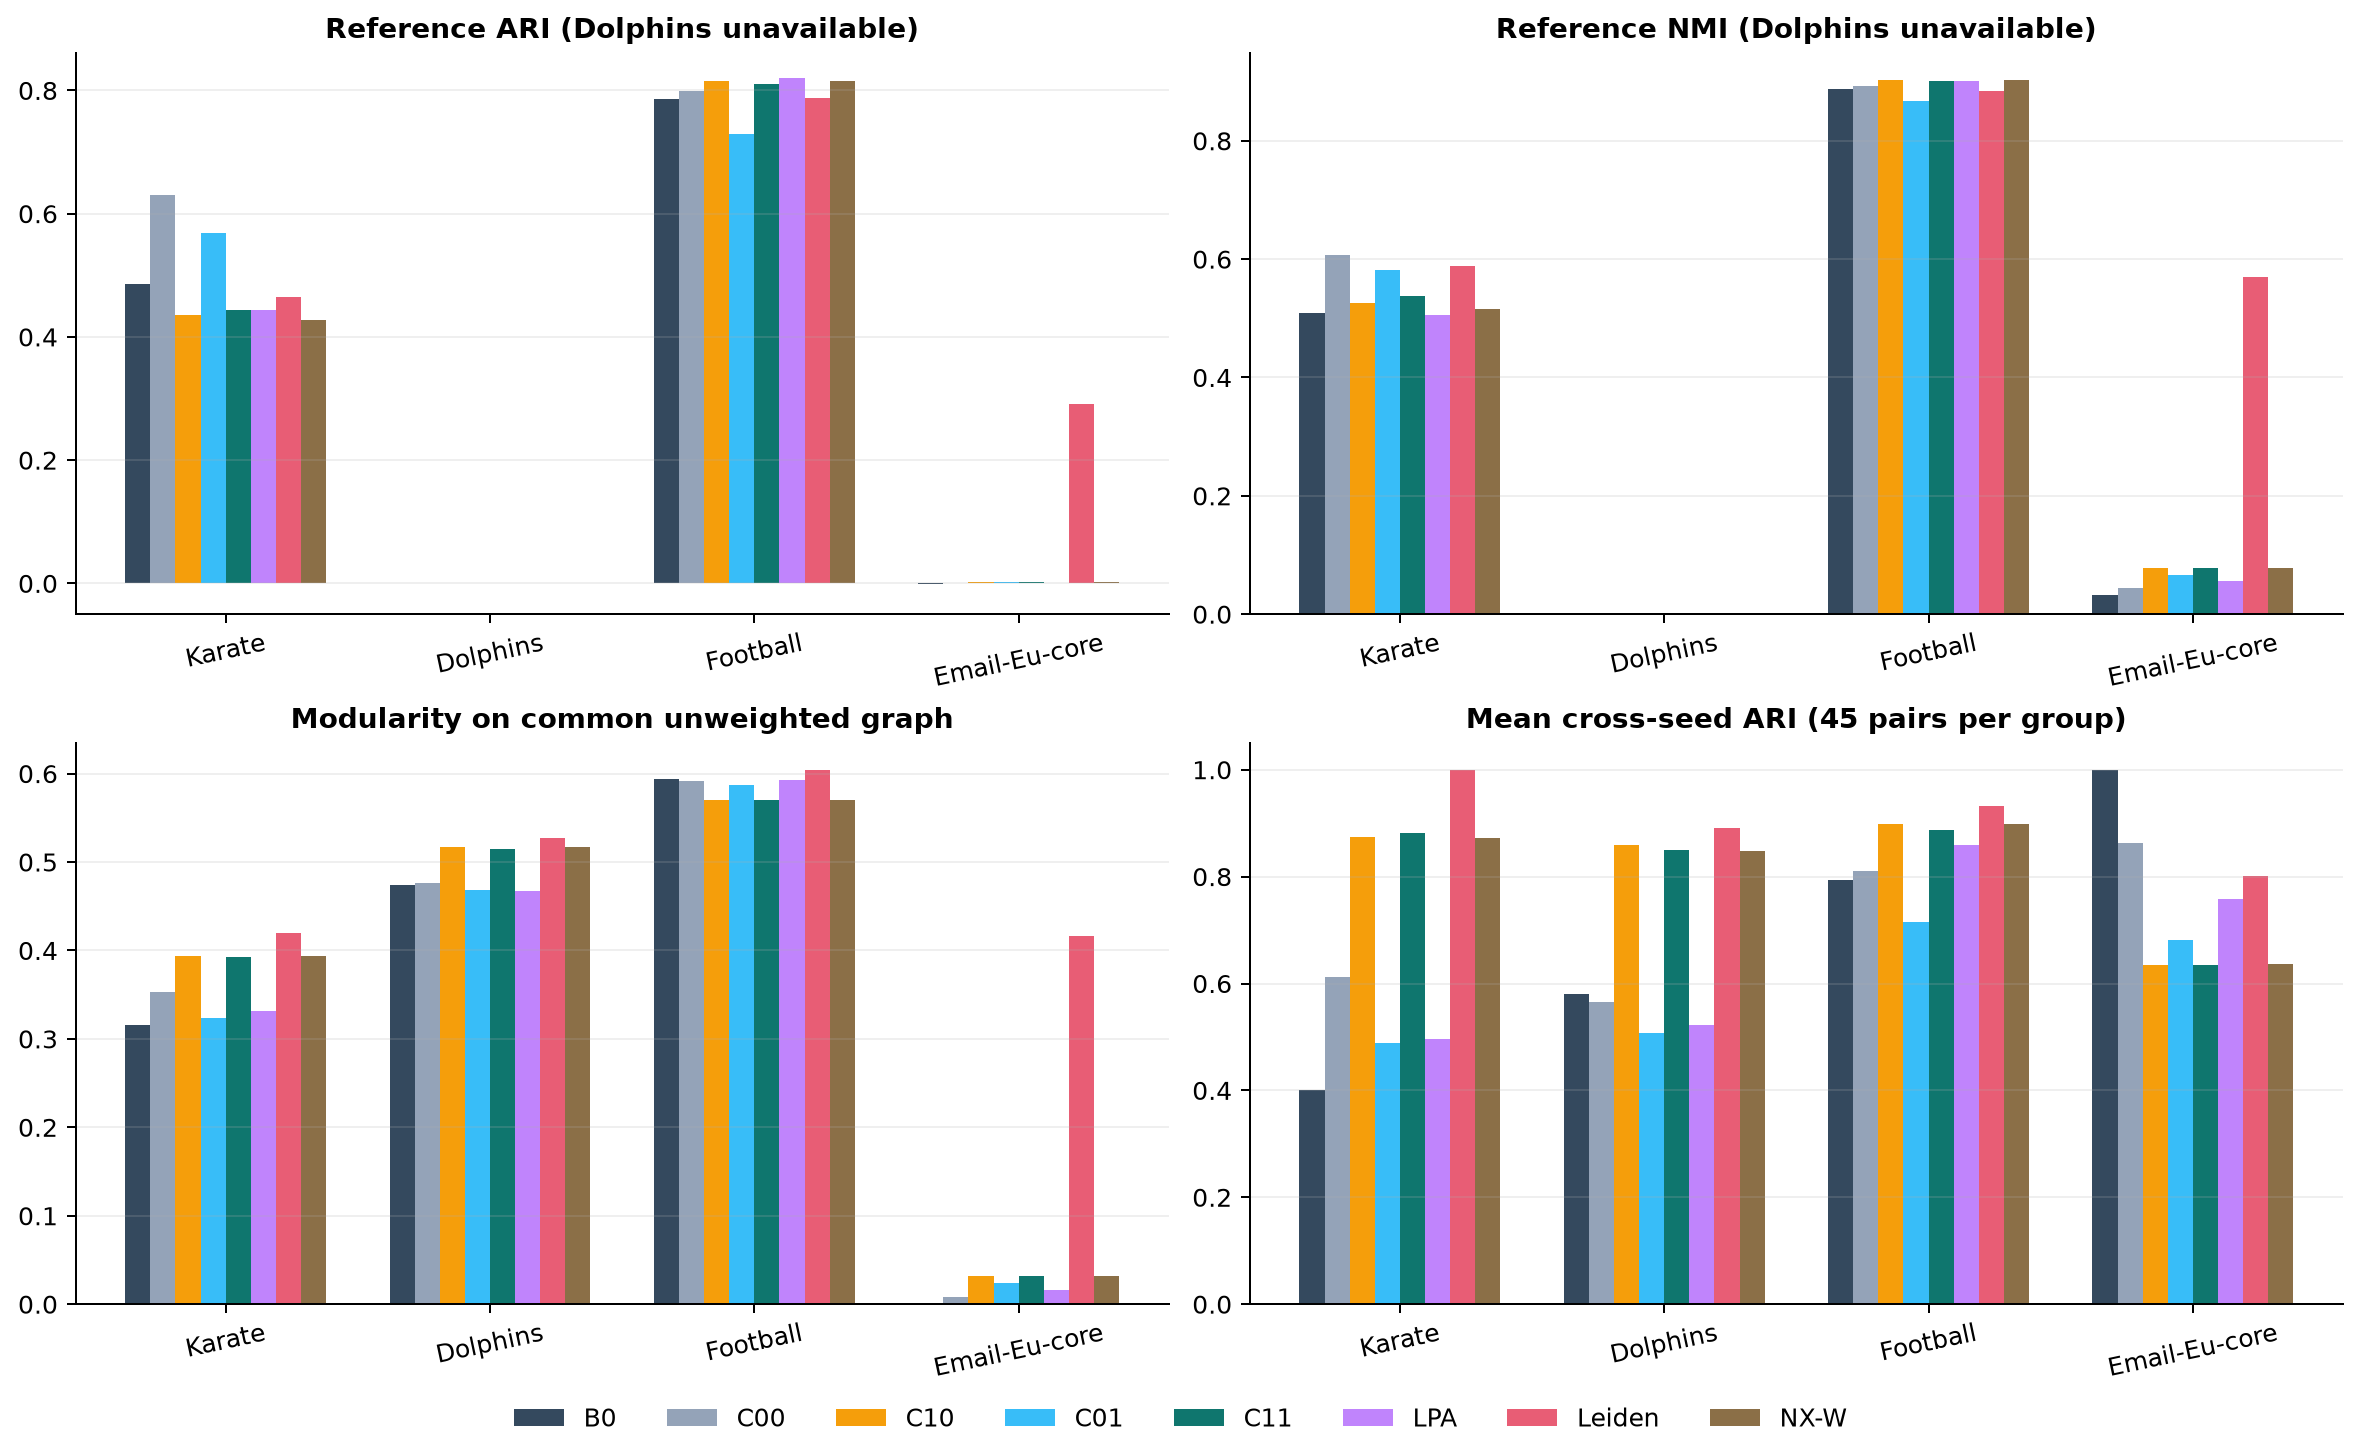

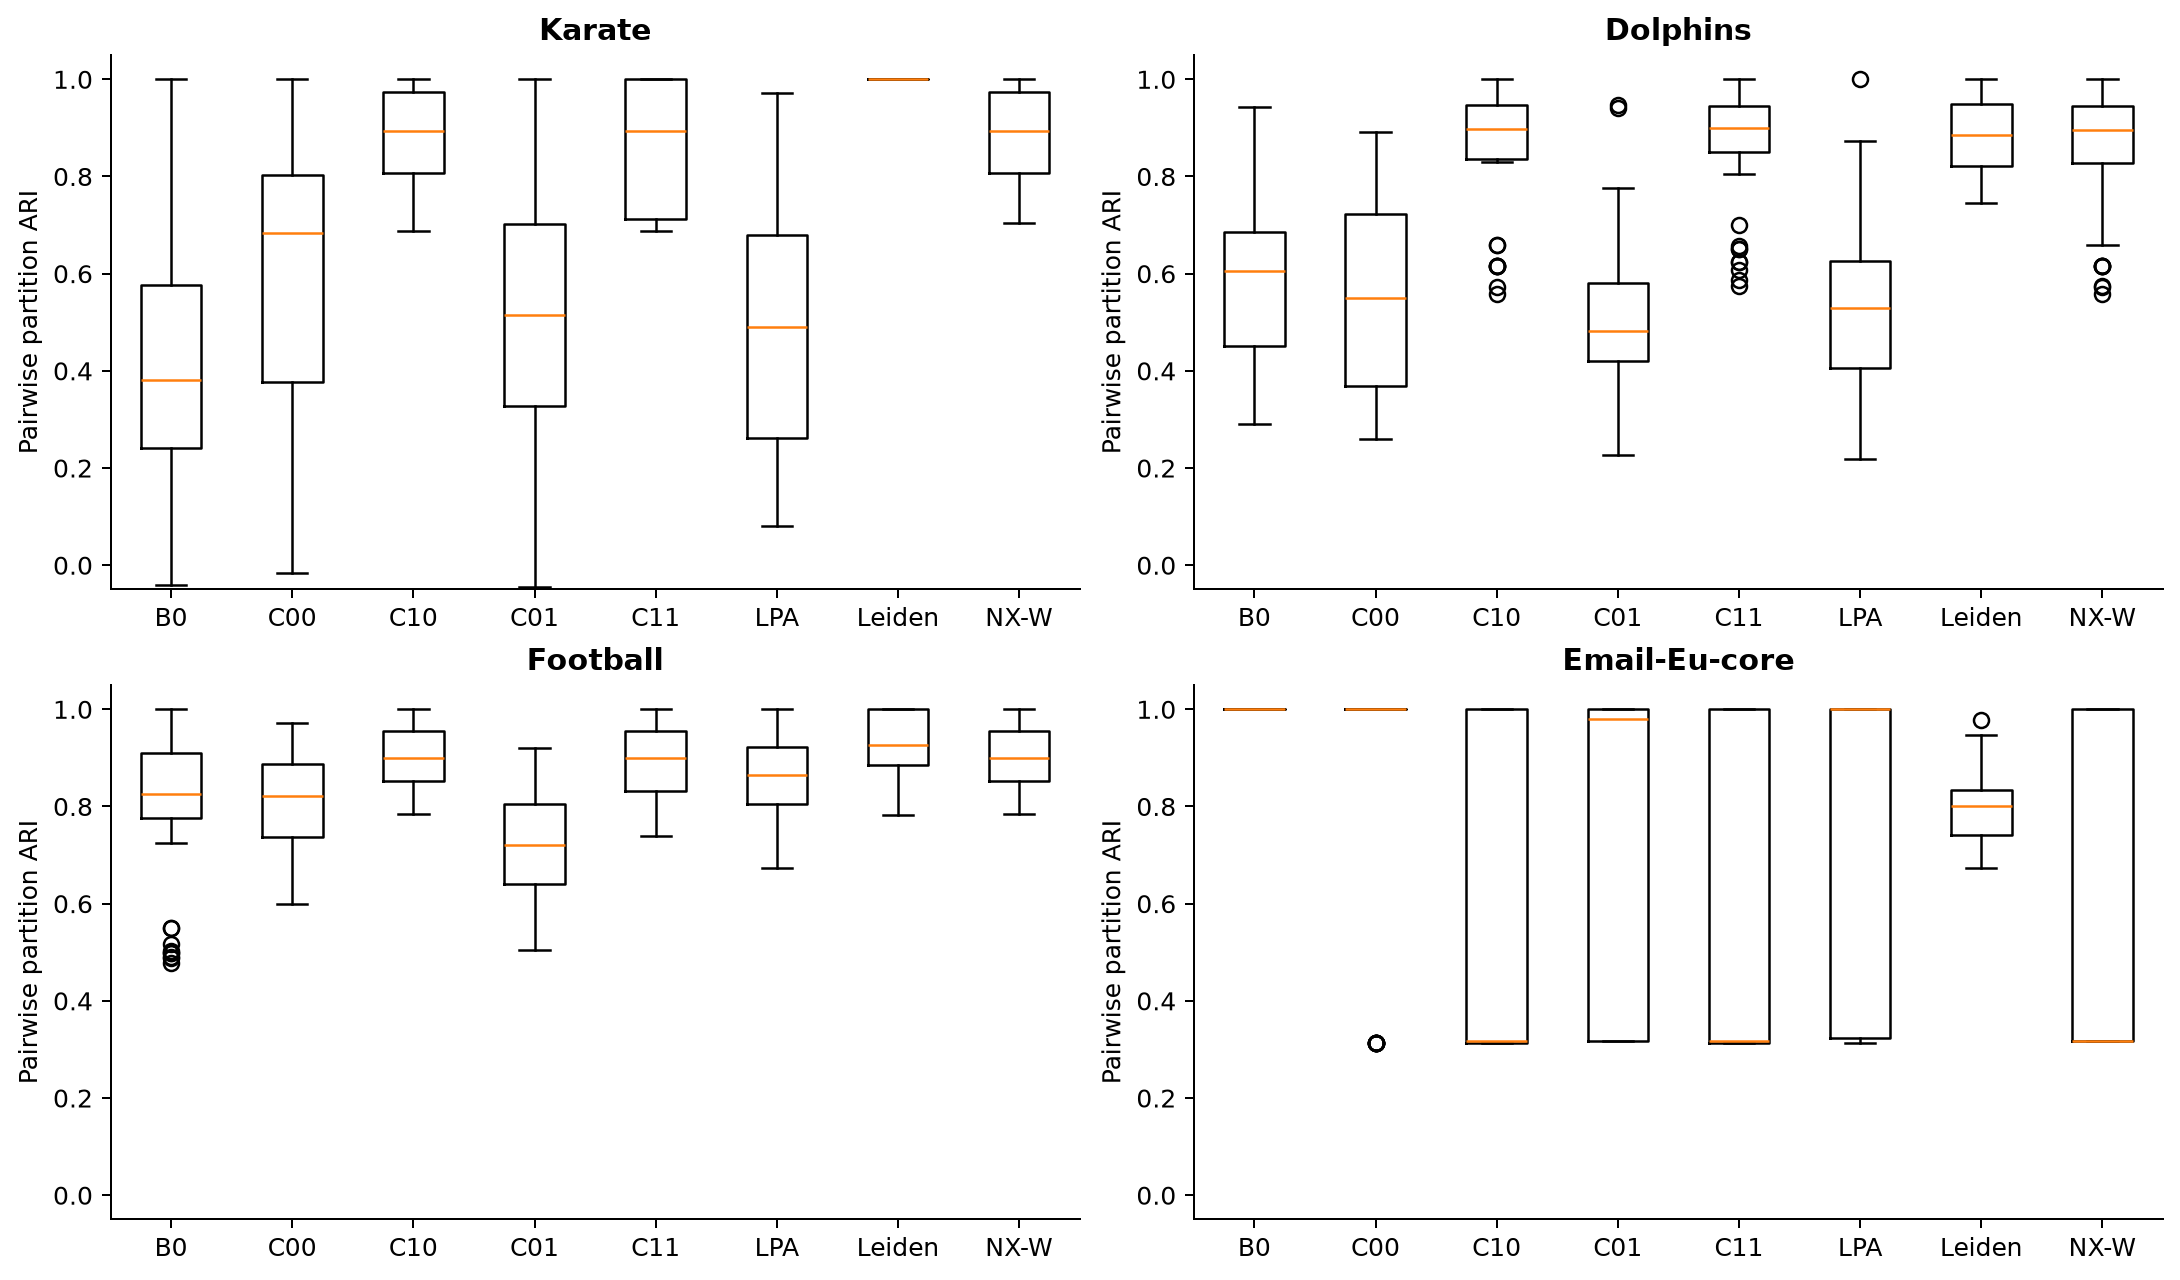

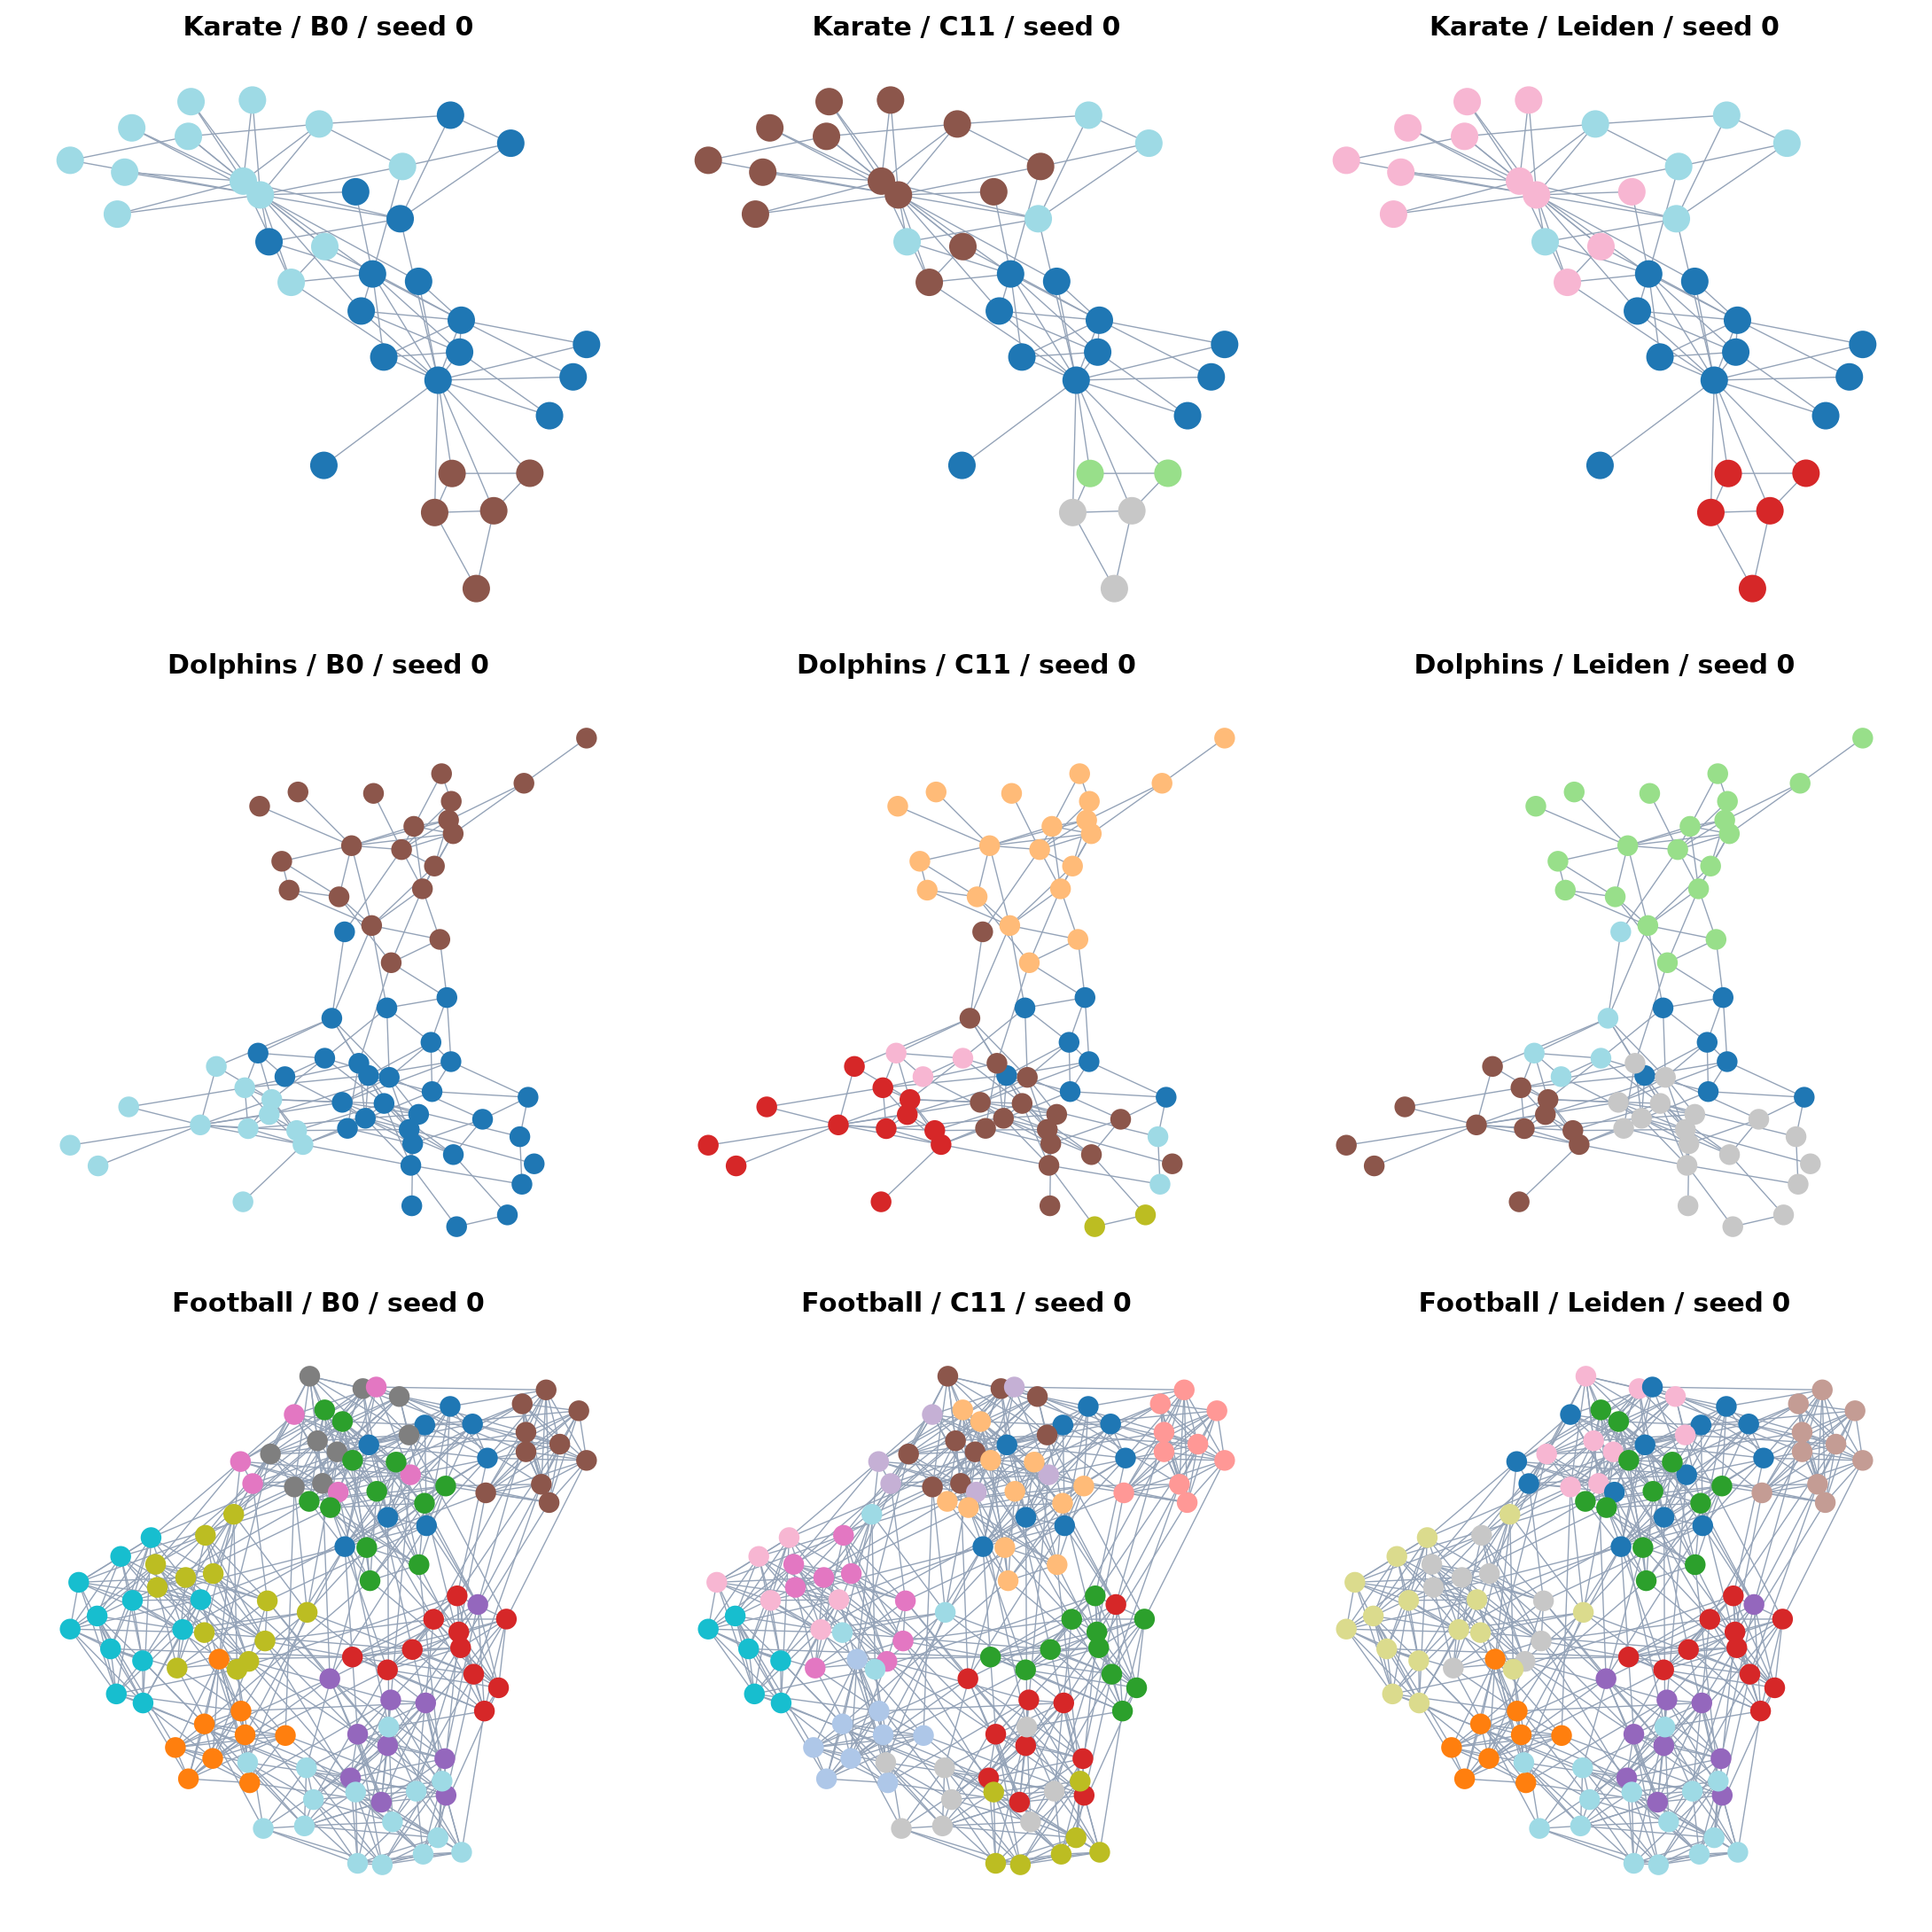

In [8]:
real = summary[summary.role.eq("real")]
display(real[["dataset_id", "method", "successful_runs", "ari_mean", "ari_std", "nmi_mean", "modularity_mean", "stability_mean", "communities_mean", "largest_fraction_mean", "method_total_s_median"]].round(5))
display(Image(filename=str(ROOT / "reports/figures/real_quality.png")))
display(Image(filename=str(ROOT / "reports/figures/stability.png")))
display(Image(filename=str(ROOT / "reports/figures/communities.png")))

### Original cell 17 — Markdown: define ablations, timing and synthetic stress

**What it explains:** the time boundary includes weight construction, optional backend conversion and detector execution. It excludes common loading, evaluation, plotting and output writing. Jobs ran sequentially in a reproducibly shuffled order after warming external imports.

**Why:** timing only the propagation loop would hide the structural-weight preparation cost, and comparing Python FLPA to compiled Leiden also reflects implementation language. Small graphs have substantial invocation overhead, so timings support descriptive measurements, not broad scalability claims. Medians of individual components can sum to a different value than the median of per-run totals.

**Data/imports:** no execution. The next cell reads recorded paired comparisons and aggregate stress results; it does not rerun the timing experiments.

## 8. Ablations, runtime and synthetic stress

Cold method time includes weight construction and backend conversion where applicable, excluding common data loading, metrics and plotting. Run order was shuffled with a separate schedule seed and methods executed sequentially. Tiny graph timings are descriptive and subject to overhead; cross-library timings also reflect compiled versus Python backends. The stacked plot shows medians of the component times; their sum need not equal the median total.

### Original cell 18 — Code cell 9: inspect ablations and increasing mixing

**Part A — paired changes:** `pd.read_csv(...paired_differences.csv)` loads comparisons produced by `aggregate()`. For each dataset and comparison, the implementation joins treatment and control runs **on algorithm seed**, subtracts control metrics from treatment metrics, and averages those differences. Ten paired runs per real graph support each row. A positive ARI difference favours treatment on reference agreement; a positive time difference means treatment was slower. Unavailable Dolphins ARI differences remain missing.

The five recorded comparisons are C00–B0 (`scheduler`, including candidate-order change), C10–C00 (weights without retention), C01–C00 (retention without weights), C11–C01 (weights with retention), and C11–B0 (complete design). These choices explain which mechanisms are held fixed. They are descriptive paired differences, not a formal causal or significance claim.

**Part B — figures:** `runtime_breakdown.png` displays measured feature/conversion/algorithm components. `synthetic_stress.png` uses the nine final synthetic graphs and shows quality, stability and time as between-block connectivity increases; its error bars describe variation across the three graph-level summaries at a condition.

**Part C — compact synthetic table:** `summary.role.eq("test")` selects final synthetic records. The dataset ID `test_sbm_medium_200` splits into `test`, `sbm`, `medium`, `200`; `.str[2]` extracts the level. Grouping by `level` and `method` averages the three graph-level means for ARI, stability and largest-group fraction. Each underlying graph-level mean already summarises ten algorithm seeds. This equal-weight average is appropriate to these equally sized groups; it is not a new detector run or a p-value calculation.

**Why synthetic graphs:** planted blocks give a known comparison partition, and changing only between-block probability makes the task systematically harder. At high mixing, FLPA-family methods can collapse into one community with ARI near zero while stability is 1; Leiden remains useful in this recorded setting. This is a key limit of the proposed design.

**Outputs/state:** `differences`, two figures, `test` with its `level` column and a condition/method table. No new timing results or graph assignments are saved.

,dataset_id,interpretation,paired_runs,ari_difference_mean,modularity_difference_mean,method_total_s_difference_mean
0,dolphins,scheduler,10,NaN,0.002128,0.000121
1,dolphins,weights_without_retention,10,NaN,0.041381,0.000939
2,dolphins,retention_without_weights,10,NaN,-0.007907,-0.000040
3,dolphins,weights_with_retention,10,NaN,0.046118,0.000921
4,dolphins,complete_design,10,NaN,0.040339,0.001001
5,email_eu_core,scheduler,10,0.000923,0.007946,0.008195
6,email_eu_core,weights_without_retention,10,0.002780,0.023817,0.152110
7,email_eu_core,retention_without_weights,10,0.001705,0.015838,0.002335
8,email_eu_core,weights_with_retention,10,0.001070,0.007990,0.147149
9,email_eu_core,complete_design,10,0.003698,0.031774,0.157679


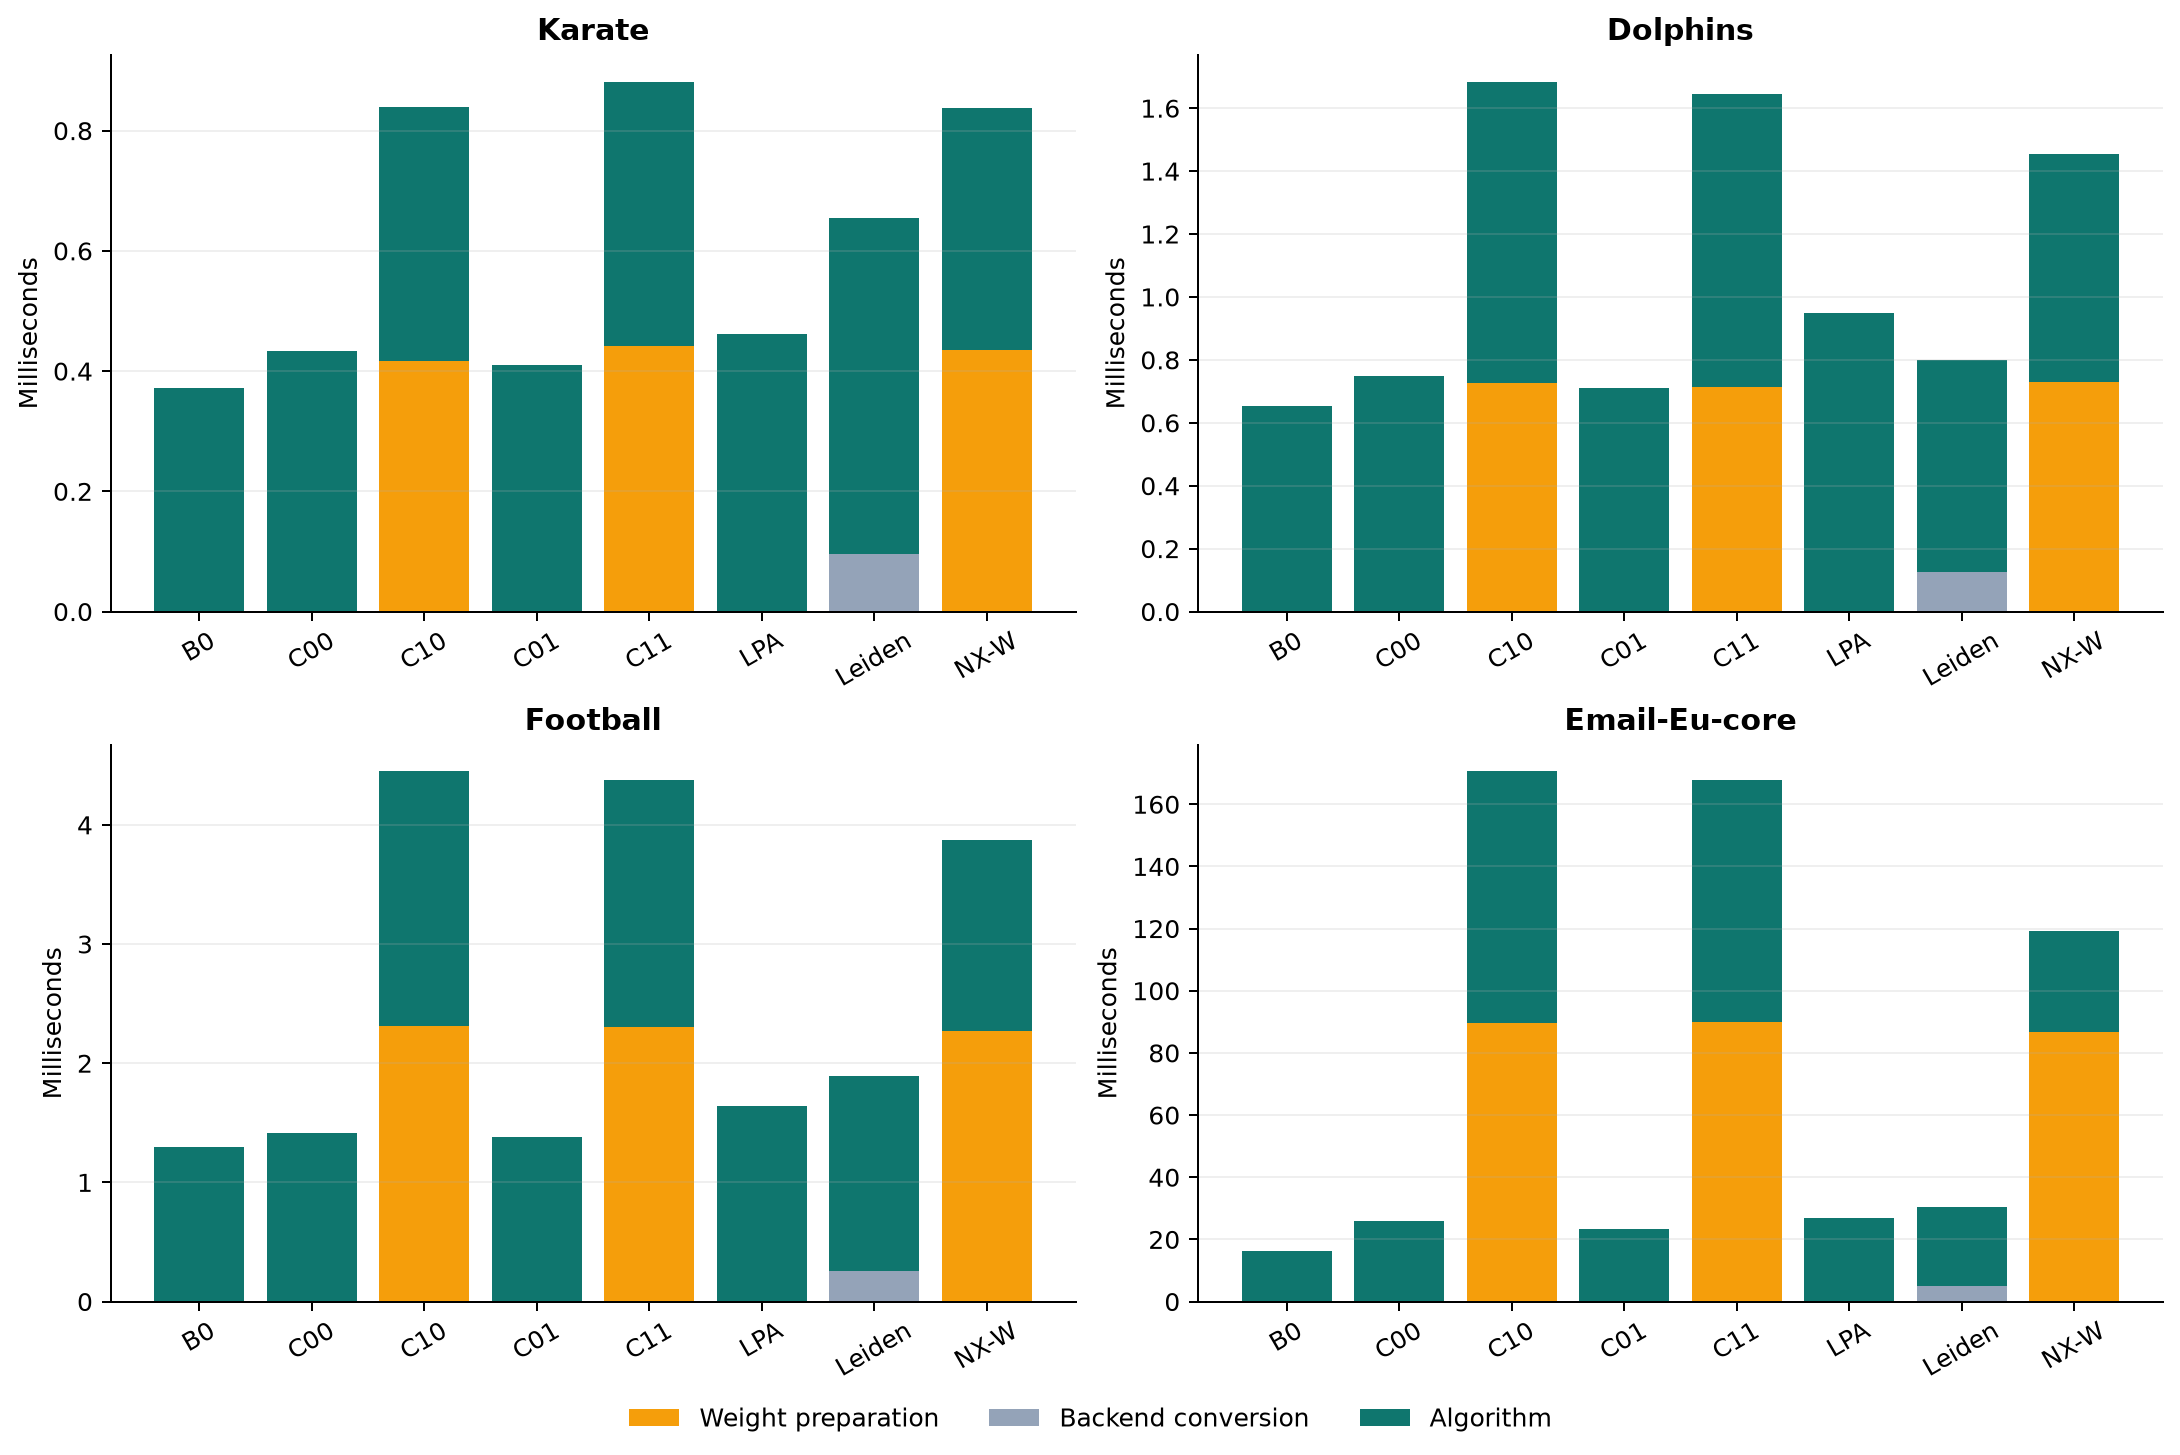

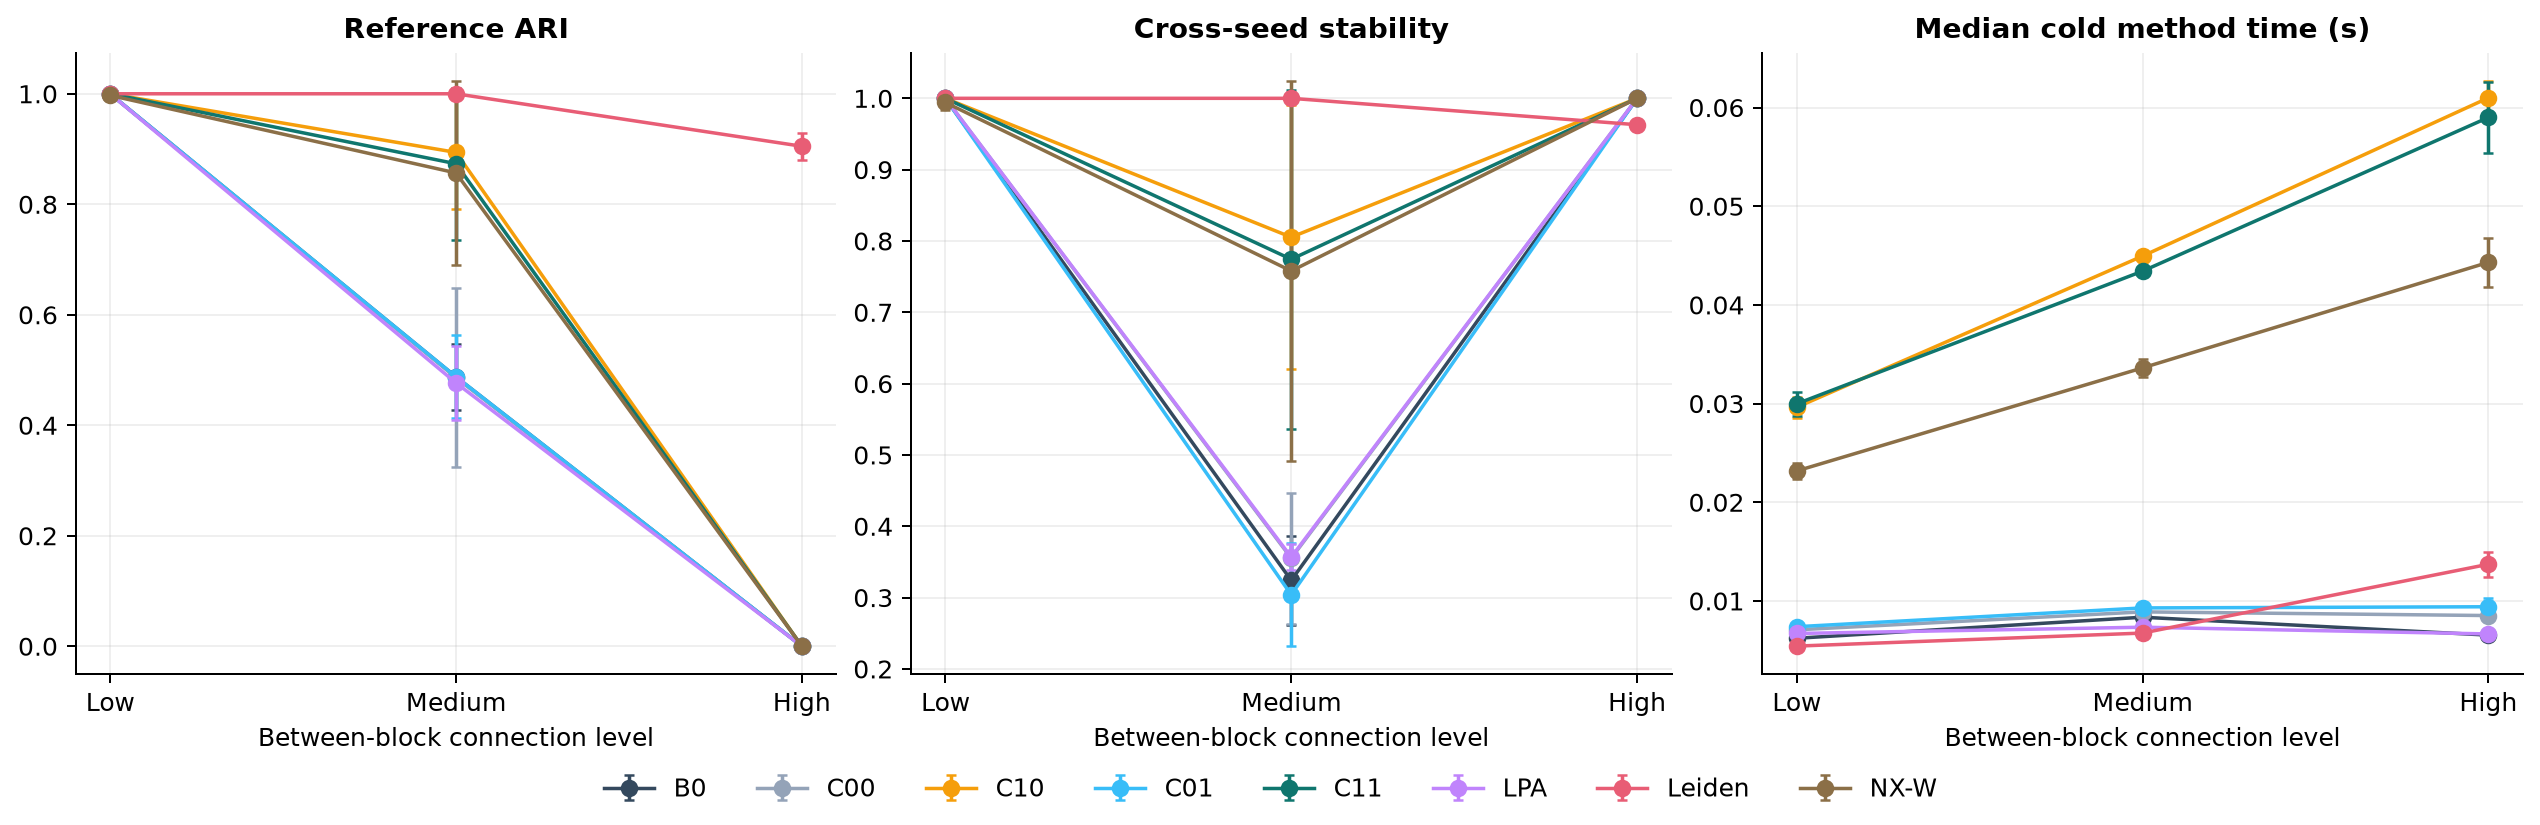

ari_mean  stability_mean  largest_fraction_mean
level  method                                                              
high   asyn_lpa               0.0000          1.0000                 1.0000
       c00_unit_random        0.0000          1.0000                 1.0000
       c01_unit_retain        0.0000          1.0000                 1.0000
       c10_weighted_random    0.0000          1.0000                 1.0000
       c11_weighted_retain    0.0000          1.0000                 1.0000
       flpa_original          0.0000          1.0000                 1.0000
       leiden_modularity      0.9050          0.9630                 0.2598
       nx_weighted_flpa       0.0000          1.0000                 1.0000
low    asyn_lpa               1.0000          1.0000                 0.2500
       c00_unit_random        1.0000          1.0000                 0.2500
       c01_unit_retain        1.0000          1.0000                 0.2500
       c10_weighted_random    1.0000          1.0000                 0.2500
       c11_weighted_retain    1.0000          1.0000                 0.2500
       flpa_original          1.0000          1.0000                 0.2500
       leiden_modularity      1.0000          1.0000                 0.2500
       nx_weighted_flpa       0.9971          0.9942                 0.2500
medium asyn_lpa               0.4767          0.3568                 0.6447
       c00_unit_random        0.4861          0.3553                 0.6372
       c01_unit_retain        0.4878          0.3039                 0.6377
       c10_weighted_random    0.8939          0.8053                 0.3352
       c11_weighted_retain    0.8733          0.7743                 0.3439
       flpa_original          0.4875          0.3241                 0.6374
       leiden_modularity      1.0000          1.0000                 0.2500
       nx_weighted_flpa       0.8567          0.7579                 0.3606

In [9]:
differences = pd.read_csv(ROOT / "results/summaries/paired_differences.csv")
display(differences[differences.dataset_id.isin(real_ids)][["dataset_id", "interpretation", "paired_runs", "ari_difference_mean", "modularity_difference_mean", "method_total_s_difference_mean"]].round(6))
display(Image(filename=str(ROOT / "reports/figures/runtime_breakdown.png")))
display(Image(filename=str(ROOT / "reports/figures/synthetic_stress.png")))
test = summary[summary.role.eq("test")].copy()
test["level"] = test.dataset_id.str.split("_").str[2]
display(test.groupby(["level", "method"])[["ari_mean", "stability_mean", "largest_fraction_mean"]].mean().round(4))

### Original cell 19 — Markdown: state findings and limitations honestly

**What it explains:** the effects differ by graph, high stability can coexist with collapse, evaluation is descriptive, and the project is a controlled empirical extension with established ingredients.

**Why:** an unsuccessful case still answers the research question. Weighting/retention did not solve the email or high-mixing synthetic failure. Ten seeds quantify randomness on a fixed graph; they do not become ten independent social networks. Three synthetic graph instances per condition also limit generalisation. The paper's very large-network speed findings cannot be claimed from this smaller study.

**Data/imports:** none execute. The statements are interpretations of the saved tables and figures, and their exact numbers are in the report. The next code cell lists the recent research evidence used in the review rather than supplying new performance results.

## 9. Interpretation and limitations

The final report gives the exact numbers. The measured evidence is mixed: structural weighting often changes quality and repeatability more than retention does. Karate shows a quality/stability tradeoff, Football shows improved reference agreement but lower modularity, and the email graph retains an unhelpful giant community for FLPA-family methods. At high synthetic between-block connectivity, those methods collapse to one community even though Leiden still recovers useful structure. Thus high stability alone does not establish useful communities or superiority.

These experiments are an independent reproduction and controlled extension, not a replication of the base paper's very large-network runtime claims. Ten seeds and three synthetic graph instances per condition support descriptive analysis, not broad significance claims. Weighted label propagation, Jaccard similarity and maximal-label retention are established mechanisms; global originality of this combination has not been established.

### Original cell 20 — Code cell 10: display the literature index

**Input:** `research/bibliography.json`, which records each reviewed paper's ID, title, year, journal, DOI, saved PDF/text paths and integrity metadata.

**How:** `read_text(encoding="utf-8")` correctly decodes titles/author names; `json.loads()` parses the list; `pd.DataFrame(...)` makes a table; the selected columns display publication details. The assertion checks that there are ten records and every recorded year is at least 2022.

**Why:** connects the implementation to a reviewable research trail. R01 is the FLPA foundation. The other papers provide related methods, prior art and discussion of alternatives. Their PDFs/texts are not features, labels or training examples for our detector. A bibliography listing does not mean all ten algorithms were reproduced.

**Scope:** the assertion alone verifies count/year, not peer review or publication metadata. The richer bibliography includes `article_type`, publisher/DOI links and PDF hashes, which are checked by the artifact validation tool. `research/review_notes.json` and `literature_review.csv` contain the actual methodological assessments.

**Output/state:** ten-paper table and a message, with `bibliography` retained for inspection. The cited recent-paper set is separate from older background references such as the original LPA and Leiden papers.

In [10]:
bibliography = json.loads((ROOT / "research/bibliography.json").read_text(encoding="utf-8"))
display(pd.DataFrame(bibliography)[["id", "title", "year", "journal", "doi"]])
assert len(bibliography) == 10 and all(p["year"] >= 2022 for p in bibliography)
print("Ten recent journal papers indexed with primary-source evidence.")

,id,title,year,journal,doi
0,R01,Large network community detection by fast labe...,2023,Scientific Reports,10.1038/s41598-023-29610-z
1,R02,A community partitioning algorithm for cyberspace,2023,Scientific Reports,10.1038/s41598-023-46556-4
2,R03,Iterative embedding and reweighting of complex...,2024,Scientific Reports,10.1038/s41598-024-68152-w
3,R04,GATFELPA integrates graph attention networks a...,2025,Scientific Reports,10.1038/s41598-024-84962-4
4,R05,Graph embedding based label propagation for co...,2025,Scientific Reports,10.1038/s41598-025-25905-5
5,R06,Community detection in networks by dynamical o...,2022,Scientific Reports,10.1038/s41598-022-20986-y
6,R07,Representative community divisions of networks,2022,Communications Physics,10.1038/s42005-022-00816-3
7,R08,Network community detection via neural embeddings,2024,Nature Communications,10.1038/s41467-024-52355-w
8,R09,Local dominance unveils clusters in networks,2024,Communications Physics,10.1038/s42005-024-01635-4
9,R10,Betweenness-driven overlapping label propagati...,2025,Annales Mathematicae et Informaticae,10.33039/ami.2025.10.012


Ten recent journal papers indexed with primary-source evidence.


### Original cell 21 — Markdown: commands for reproducing the whole workflow

**What it explains:** the CLI stages `prepare`, `select`, `run`, `summarize`, and `plot`, plus the correctness suite. These are instructions inside a text block; reading or executing this Markdown cell does not run the commands.

**Why separate commands:** rerunning all experiments can create new attempts and timing measurements. The original notebook normally inspects bundled evidence and runs small examples, preserving a clear distinction between the official run record and a new reproduction. The README provides commands using a separate `reproduction` root to avoid mixing attempts.

**Practical sequence:** install pinned dependencies and the package; register/select the kernel; use the existing notebook to inspect saved results; for a complete reproduction, follow the README's separate-root workflow, then inspect that root's summaries. First-time acquisition requires internet, while the bundled graphs and results can be inspected offline after installing dependencies. Repeated attempts need explicit selection/archiving before plotting final tables.

**End of the original notebook:** everything after its reproduced cell below is an added teaching demonstration. These extras are labelled separately and do not change the numbering of the original 21 cells.

## 10. Re-run instructions

Install the pinned dependencies and the package, then run:

```text
python -m sna_project prepare
python -m sna_project select
python -m sna_project run --config configs/real.yaml
python -m sna_project run --config configs/stress.yaml
python -m sna_project summarize
python -m sna_project plot
```

Use a fresh results directory for a complete rerun, or archive existing attempts as described in README.md. Default notebook execution audits bundled measured results and reruns live examples; it does not automatically overwrite the final experimental record. `pytest -q` runs the correctness suite. The submission contains the complete package, configurations, raw/processed data, run records and report-building scripts.

## Extra demonstration A — inspect the exact data that enters the code

This additional cell previews Karate's **mapping, edges and reference labels** side by side, then previews one saved predicted partition. It also shows the loaded function's source-file path. These are file reads only. `reference_group` is the supplied answer for evaluation; `community_id` is a detector's prediction. Joining on `internal_id` makes the alignment explicit even when original node numbers differ.

The displayed combined table is for human inspection. The detector was called earlier with the graph alone, not with this joined table.

In [11]:
print("Source package loaded from:", inspect.getfile(load_prepared))
print("Project root:", ROOT)
preview_dir = ROOT / "data/processed/karate"
preview_nodes = pd.read_csv(preview_dir / "nodes.csv")
preview_edges = pd.read_csv(preview_dir / "edges.csv")
preview_truth = pd.read_csv(preview_dir / "labels.csv")
for filename, frame in [("nodes.csv", preview_nodes), ("edges.csv", preview_edges),
                        ("labels.csv (evaluation reference)", preview_truth)]:
    print(filename, "rows =", len(frame), "columns =", list(frame.columns))
    display(frame.head())
preview_row = runs[(runs.dataset_id == "karate") &
                   (runs.method == "c11_weighted_retain") & (runs.seed == 0)].iloc[0]
preview_path = ROOT / "results/runs" / preview_row.attempt / preview_row.run_id / "partition.csv"
preview_prediction = pd.read_csv(preview_path)
print("Saved prediction:", preview_path.relative_to(ROOT).as_posix())
display(preview_nodes.merge(preview_truth, on="internal_id", validate="one_to_one")
        .merge(preview_prediction, on="internal_id", validate="one_to_one").head(10))
assert len(preview_nodes) == 34 and len(preview_edges) == 78
assert all(not attrs for _, attrs in load_prepared(ROOT, "karate").graph.nodes(data=True))

Source package loaded from: D:\sem7\SNA\Final_Submission_230968316\src\sna_project\data.py
Project root: D:\sem7\SNA\Final_Submission_230968316
nodes.csv rows = 34 columns = ['internal_id', 'original_id', 'original_name']


,internal_id,original_id,original_name
0,0,0,0
1,1,1,1
2,2,10,10
3,3,11,11
4,4,12,12


edges.csv rows = 78 columns = ['source', 'target']


,source,target
0,0,1
1,0,2
2,0,3
3,0,4
4,0,5


labels.csv (evaluation reference) rows = 34 columns = ['internal_id', 'reference_group']


,internal_id,reference_group
0,0,0
1,1,0
2,2,0
3,3,0
4,4,0


Saved prediction: results/runs/final_real_v1_20261026T145257401214Z/karate__c11_weighted_retain__seed0/partition.csv


,internal_id,original_id,original_name,reference_group,community_id
0,0,0,0,0,0
1,1,1,1,0,0
2,2,10,10,0,1
3,3,11,11,0,0
4,4,12,12,0,0
5,5,13,13,0,0
6,6,14,14,1,2
7,7,15,15,1,2
8,8,16,16,0,3
9,9,17,17,0,0


## Extra demonstration B — trace one weighted vote and one retention tie

The next cell uses the original six-node toy topology and **hand-chosen temporary community assignments** to show the update arithmetic. These assignments are illustrative algorithm state, not dataset truth and not measured final outputs. At node 2, neighbours 0 and 1 vote for group 10 through locally embedded edges, and neighbour 3 votes for group 20 through the bridge. We use the real selected lambda 0.25 here.

A separate three-node path then creates an exact unit-weight tie: the centre already has label 10, and its neighbours vote once for 10 and once for 20. Retention keeps 10 because it is maximal; the random tie rule would sample from both candidates and could also happen to keep 10. The demonstration calls the actual scoring/candidate helpers used by `propagate()`.

In [12]:
from sna_project.algorithms import label_support, maximal_candidates
vote_graph = apply_weights(example, edge_similarity(example), LAMBDA)
vote_labels = {0: 10, 1: 10, 2: 20, 3: 20, 4: 30, 5: 30}
vote_node = 2
display(pd.DataFrame([{"neighbour": v, "neighbour_label": vote_labels[v],
                       "weight": vote_graph[vote_node][v]["structural_weight"]}
                      for v in vote_graph[vote_node]]))
vote_scores = label_support(vote_graph, vote_labels, vote_node, "structural_weight")
print("Summed support at node 2:", vote_scores)
assert np.isclose(vote_scores[10], 2.125) and vote_scores[20] == 1.0
vote_candidates = maximal_candidates(vote_scores, weighted=True, atol=1e-12, rtol=1e-12)
assert vote_candidates == [10]
print("Maximal label:", vote_candidates, "-> node 2 changes from 20 to 10")
tie_graph = nx.path_graph(3)
tie_labels = {0: 10, 1: 10, 2: 20}
tie_scores = label_support(tie_graph, tie_labels, 1, None)
tie_candidates = maximal_candidates(tie_scores, weighted=False, atol=1e-12, rtol=1e-12)
assert set(tie_candidates) == {10, 20} and tie_labels[1] in tie_candidates
print("Separate tie example:", tie_scores, "candidates:", tie_candidates)
print("Retention keeps current label", tie_labels[1], "; random ties sample either candidate.")

,neighbour,neighbour_label,weight
0,1,10,1.0625
1,0,10,1.0625
2,3,20,1.0000


Summed support at node 2: {10: 2.125, 20: 1.0}
Maximal label: [10] -> node 2 changes from 20 to 10
Separate tie example: {10: 1, 20: 1} candidates: [10, 20]
Retention keeps current label 10 ; random ties sample either candidate.


## Extra demonstration C — where the 45 stability pairs come from

This added cell loads the ten saved **Karate C11** predictions, compares every unordered pair with `pairwise_stability()`, and matches the mean to its official summary row. It uses predicted partitions only; it does **not** compare against Karate's faction labels. ARI compares memberships independently of community-ID numbering.

This is a live explanation of a computation the original notebook only displayed through summaries/images. Repeating a partition across seeds can yield stability 1 even if reference agreement is poor. The pairs share runs, so they are dependent observations.

In [13]:
stability_rows = runs[(runs.dataset_id == "karate") &
                      (runs.method == "c11_weighted_retain")].sort_values("seed")
stability_partitions = {}
for stability_row in stability_rows.itertuples(index=False):
    stability_path = ROOT / "results/runs" / stability_row.attempt / stability_row.run_id / "partition.csv"
    stability_frame = pd.read_csv(stability_path)
    stability_partitions[stability_row.run_id] = {
        int(u): int(c) for u, c in stability_frame.itertuples(index=False, name=None)}
stability_recomputed = pd.DataFrame(pairwise_stability(stability_partitions))
stability_saved = summary[(summary.dataset_id == "karate") &
                          (summary.method == "c11_weighted_retain")].iloc[0]
assert len(stability_partitions) == 10 and len(stability_recomputed) == 10 * 9 // 2 == 45
assert np.isclose(stability_recomputed.stability_ari.mean(), stability_saved.stability_mean,
                  atol=1e-12, rtol=1e-12)
display(stability_recomputed.head())
print("10 seeds ->", len(stability_recomputed), "unordered pairs")
print("Recomputed mean stability:", stability_recomputed.stability_ari.mean())
print("Official summary stability:", stability_saved.stability_mean)

,run_a,run_b,stability_ari
0,karate__c11_weighted_retain__seed0,karate__c11_weighted_retain__seed1,0.712057
1,karate__c11_weighted_retain__seed0,karate__c11_weighted_retain__seed2,0.973673
2,karate__c11_weighted_retain__seed0,karate__c11_weighted_retain__seed3,1.000000
3,karate__c11_weighted_retain__seed0,karate__c11_weighted_retain__seed4,1.000000
4,karate__c11_weighted_retain__seed0,karate__c11_weighted_retain__seed5,1.000000


10 seeds -> 45 unordered pairs
Recomputed mean stability: 0.8809378387465613
Official summary stability: 0.8809378387465613


## Extra demonstration D — verify this explanation against the original cells

This companion stores the one-based original position and a source-text hash with every reproduced cell. The next check compares **all 21 reproduced sources** against the current original notebook. It also checks that the saved final-run records refer to the current five scientific core modules and that final dataset/method/seed combinations are unique. These checks make the explanation traceable to the actual implementation being submitted.

Changing an original cell later should trigger regeneration of this companion. The scientific fingerprint covers `algorithms.py`, `contracts.py`, `data.py`, `evaluation.py` and `experiment.py`; explanation/report tooling does not change that scientific fingerprint.

In [14]:
import hashlib
import nbformat
from sna_project.experiment import code_fingerprint
original_document = nbformat.read(ROOT / "SNA_Project_with_Results.ipynb", as_version=4)
companion_document = nbformat.read(ROOT / "explaination.ipynb", as_version=4)
mapped_cells = [c for c in companion_document.cells if "original_cell_index" in c.metadata]
assert len(mapped_cells) == len(original_document.cells) == 21
for mapped_cell, original_cell in zip(mapped_cells, original_document.cells):
    source_hash = hashlib.sha256(original_cell.source.encode("utf-8")).hexdigest()
    assert mapped_cell.source == original_cell.source
    assert mapped_cell.cell_type == original_cell.cell_type
    assert mapped_cell.metadata.original_source_sha256 == source_hash
assert sum(c.cell_type == "code" for c in mapped_cells) == 10
assert not runs.duplicated(["dataset_id", "method", "seed"]).any()
assert runs.code_sha256.eq(code_fingerprint()).all()
print("Verified: all 21 original cell sources, including all 10 code cells.")
print("Verified: 1,040 unique final experiments match the current scientific source fingerprint.")
print("Fingerprint:", code_fingerprint())

Verified: all 21 original cell sources, including all 10 code cells.
Verified: 1,040 unique final experiments match the current scientific source fingerprint.
Fingerprint: 1cd87826d0fc1ce23dee479206a27179bd2dd069968722dc7d97a60ba4aa8df6


## Short answers for presenting the project

| Question | Answer supported by this implementation |
|---|---|
| What is the project trying to improve? | The usefulness and repeatability of community assignments from fast label propagation. |
| What is the input? | A simple undirected graph; weighted variants add a topology-derived edge attribute. |
| What is the output? | One predicted community ID for every node, with diagnostics and evaluation records. |
| What comes from the base paper? | Original FLPA's asynchronous update and filtered queue; the paper also discusses established retention. |
| What did we implement as an extension? | Fixed Jaccard edge weights, explicit retention and queue switches, development-only lambda selection and controlled evaluation. |
| What is the novelty claim? | A specific empirical design and evaluation; global originality of the combination is unproven. |
| Where is model training? | There is no neural training; lambda selection is an 80-run development procedure. |
| Are research papers used as the input dataset? | No. Papers justify/compare methods; graph sources provide nodes/edges. |
| Do known labels guide detection? | No. They score predictions and tune lambda on separate development graphs. |
| Why multiple seeds? | To measure randomness and repeatability for the same graph and method. |
| Why compare C10 with C00 and C11 with C01? | To change weighting while holding the other controlled choices fixed. |
| Is higher stability always better? | No. One collapsed group can be stable but uninformative. |
| Did the extension always improve results? | No. The recorded effects are mixed and include email/high-mixing failures. |
| What proves that the notebook shows real results? | Bundled assignments/records, metric recomputation, source fingerprints, baseline parity and executed outputs provide traceable evidence. |

For exact measured numbers, use the displayed tables and `Project_Report.pdf`. For implementation details, read `src/sna_project/algorithms.py`, `data.py`, `evaluation.py` and `experiment.py` beside their mapped cells. Rebuild this companion with `python tools/build_explanation.py`; it copies the original sources, executes the explanations' examples and saves outputs to `explaination.ipynb`.